In [1]:
import pandas as pd

In [2]:
df_metadata = pd.read_csv("merge_ecac/metadata.csv")

In [3]:
df_metadata.shape

(1348, 27)

In [4]:
df_metadata.head()

,Audio_Song,Lyric_Song,Quadrant,AllMusic Id,AllMusic Extraction Date,Artist,Title,Relevance,Year,LowestYear,...,ThemeWeights,Styles,StyleWeights,AppearancesTrackIDs,AppearancesAlbumIDs,Sample,SampleURL,ActualYear,num_Genres,num_MoodsAll
0,MT0002007417,MT0002007417,Q3,MT0002007417,Old,Marlene Dietrich,Falling in Love Again,1.040315,27/07/2004,1994-??-??,...,"5,6,7,8,8,9,9","Cabaret,Torch Songs,Traditional Pop","7,8,8","MT0002007417,MT0033924988","MW0000204999,MW0001114125",1.0,http://rovimusic.rovicorp.com/playback.mp3?c=j...,2004,NaN,NaN
1,MT0009263768,MT0009263768,Q3,MT0009263768,Old,George Strait,Four Down and Twelve Across,NaN,NaN,NaN,...,"9,9,9","Contemporary Country,New Traditionalist","5,9",NaN,NaN,1.0,http://rovimusic.rovicorp.com/playback.mp3?c=p...,NaN,NaN,NaN
2,MT0030214520,MT0030214520,Q2,MT0030214520,Old,Gorilla Biscuits,Forgotten,1.020054,1989-??-??,1988-??-??,...,NaN,"Alternative/Indie Rock,Contemporary Pop/Rock,I...","7,7,7,9,9","MT0002293082,MT0003076885,MT0004145917,MT00051...","MW0000199609,MW0000199609,MW0000199609,MW00001...",1.0,http://rovimusic.rovicorp.com/playback.mp3?c=W...,1989,NaN,NaN
3,MT0000097948,MT0000097948,Q4,MT0000097948,Old,Nat King Cole,"Baby, Baby All the Time",1.081924,07/10/2003,NaN,...,"7,8,9","Swing,Traditional Pop,Vocal Jazz","7,8,9","MT0000097948,MT0006106958,MT0006392619,MT00072...","MW0000027198,MW0000027198,MW0000044908,MW00000...",1.0,http://rovimusic.rovicorp.com/playback.mp3?c=K...,2003,NaN,NaN
4,MT0009005900,MT0009005900,Q1,MT0009005900,Old,Merle Haggard,I Made the Prison Band,NaN,1967-??-??,1967-??-??,...,NaN,Traditional Country,5,"MT0000022647,MT0004898729,MT0004988534,MT00057...","MW0000015847,MW0000176873,MW0000176873,MW00004...",1.0,http://rovimusic.rovicorp.com/playback.mp3?c=d...,1967,NaN,NaN


# 4. Limpeza dos Dados

## 4.1 Duplicados

### 4.1.1 Identificação de linhas idênticas

O primeiro passo consiste em identificar linhas que sejam completamente idênticas em todas as colunas.

In [6]:
duplicate_mask = df_metadata.duplicated(keep=False)

identical_rows = df_metadata[duplicate_mask]

print("Total rows:", len(df_metadata))
print("Rows involved in exact duplication:", len(identical_rows))
print("Extra duplicate copies:", df_metadata.duplicated().sum())

Total rows: 1348
Rows involved in exact duplication: 50
Extra duplicate copies: 25


In [7]:
display(
    identical_rows[
        ["Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ].sort_values("Audio_Song")
)

,Audio_Song,Lyric_Song,Artist,Title,Quadrant
971,A071-70,L121-70,Ben Folds Five,Brick,Q3
131,A071-70,L121-70,Ben Folds Five,Brick,Q3
103,A132-121,L022-121,The Ten Tenors,"Bee Gees Medley: Staying Alive, You Should Be ...",Q1
556,A132-121,L022-121,The Ten Tenors,"Bee Gees Medley: Staying Alive, You Should Be ...",Q1
1108,MT0000408441,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3
338,MT0000408441,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3
544,MT0000685538,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3
640,MT0000685538,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3
179,MT0000886390,MT0000886390,Dolly Parton,Randy,Q1
378,MT0000886390,MT0000886390,Dolly Parton,Randy,Q1


**Resposta:** O conjunto de dados contém 25 cópias exatamente duplicadas. Estas correspondem a 25 pares de linhas completamente idênticas, o que significa que 50 linhas estão envolvidas em duplicação exata. Portanto, 25 linhas são cópias redundantes.

### 4.1.2 Identificação da mesma gravação

Para determinar se diferentes linhas representam a mesma gravação, serão comparados quatro tipos de evidência: as colunas de identificação, o artista e o título, a letra e o áudio.

In [8]:
df_metadata.columns.tolist()

['Audio_Song',
 'Lyric_Song',
 'Quadrant',
 'AllMusic Id',
 'AllMusic Extraction Date',
 'Artist',
 'Title',
 'Relevance',
 'Year',
 'LowestYear',
 'Duration',
 'Moods',
 'MoodsAll',
 'MoodsAllWeights',
 'Genres',
 'GenreWeights',
 'Themes',
 'ThemeWeights',
 'Styles',
 'StyleWeights',
 'AppearancesTrackIDs',
 'AppearancesAlbumIDs',
 'Sample',
 'SampleURL',
 'ActualYear',
 'num_Genres',
 'num_MoodsAll']

In [9]:
identificadores = ["Audio_Song", "Lyric_Song", "AllMusic Id"]

for coluna in identificadores:
    print(f"{coluna}:")
    print(f"  Valores únicos: {df_metadata[coluna].nunique(dropna=True)}")
    print(f"  Valores ausentes: {df_metadata[coluna].isna().sum()}")
    print(f"  Valores repetidos: {df_metadata[coluna].duplicated().sum()}")
    print()

Audio_Song:
  Valores únicos: 1323
  Valores ausentes: 0
  Valores repetidos: 25

Lyric_Song:
  Valores únicos: 1323
  Valores ausentes: 0
  Valores repetidos: 25

AllMusic Id:
  Valores únicos: 1320
  Valores ausentes: 0
  Valores repetidos: 28



In [10]:
allmusic_repetidos = df_metadata[
    df_metadata.duplicated("AllMusic Id", keep=False)
].sort_values("AllMusic Id")

display(
    allmusic_repetidos[
        ["AllMusic Id", "Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ]
)

,AllMusic Id,Audio_Song,Lyric_Song,Artist,Title,Quadrant
1108,MT0000408441,MT0000408441,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3
338,MT0000408441,MT0000408441,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3
544,MT0000685538,MT0000685538,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3
640,MT0000685538,MT0000685538,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3
378,MT0000886390,MT0000886390,MT0000886390,Dolly Parton,Randy,Q1
179,MT0000886390,MT0000886390,MT0000886390,Dolly Parton,Randy,Q1
353,MT0001189913,MT0001189913,MT0001189913,Kay Kyser,"(I Got Spurs That) Jingle, Jangle, Jingle",Q1
701,MT0001189913,MT0001189913,MT0001189913,Kay Kyser,"(I Got Spurs That) Jingle, Jangle, Jingle",Q1
1283,MT0001841416,MT0001841416,MT0001841416,Lightnin' Hopkins,Shotgun (Blues),Q3
1200,MT0001841416,MT0001841416,MT0001841416,Lightnin' Hopkins,Shotgun (Blues),Q3


In [12]:
# Remove apenas as cópias exatamente idênticas para investigar
# repetições de identificadores entre registros diferentes
df_sem_duplicados_exatos = df_metadata.drop_duplicates()

print("Linhas originais:", len(df_metadata))
print("Linhas após remover cópias exatas:", len(df_sem_duplicados_exatos))

Linhas originais: 1348
Linhas após remover cópias exatas: 1323


In [13]:
allmusic_conflitos = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos.duplicated("AllMusic Id", keep=False)
].sort_values("AllMusic Id")

print("Linhas com AllMusic Id repetido após remover duplicados exatos:",
      len(allmusic_conflitos))

print("AllMusic Id distintos envolvidos:",
      allmusic_conflitos["AllMusic Id"].nunique())

display(
    allmusic_conflitos[
        ["AllMusic Id", "Audio_Song", "Lyric_Song", "Artist", "Title", "Quadrant"]
    ]
)

Linhas com AllMusic Id repetido após remover duplicados exatos: 4
AllMusic Id distintos envolvidos: 1


,AllMusic Id,Audio_Song,Lyric_Song,Artist,Title,Quadrant
97,not_found,A170,L170,Silverchair,Suicidal Dream,Q3
611,not_found,A179,L179,Monica Brown,One People One Land,Q4
935,not_found,A109-138,L159-138,Diana Krall,Love is Where You Are,Q4
1347,not_found,A165,L165,Amata,Water Song,Q4


#### Evidência pelos identificadores

Foram inicialmente analisadas as colunas `Audio_Song`, `Lyric_Song` e `AllMusic Id`. Os identificadores `Audio_Song` e `Lyric_Song` apresentam 25 repetições cada, correspondentes às 25 cópias exatas identificadas anteriormente.

A coluna `AllMusic Id` apresenta 28 repetições. Contudo, após a remoção das cópias exatas, verificou-se que as três repetições adicionais são explicadas por quatro registos distintos contendo o valor `not_found`. Este valor representa a ausência de um identificador válido e, portanto, não constitui evidência de que estas quatro linhas correspondam à mesma gravação.

In [14]:
for coluna in ["Audio_Song", "Lyric_Song"]:
    repetidos = df_sem_duplicados_exatos[
        df_sem_duplicados_exatos.duplicated(coluna, keep=False)
    ]

    print(f"{coluna}:")
    print(f"  Linhas envolvidas em repetição: {len(repetidos)}")
    print(f"  Identificadores repetidos: {repetidos[coluna].nunique()}")
    print()

Audio_Song:
  Linhas envolvidas em repetição: 0
  Identificadores repetidos: 0

Lyric_Song:
  Linhas envolvidas em repetição: 0
  Identificadores repetidos: 0



In [16]:
artist_title_repetidos = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos.duplicated(
        subset=["Artist", "Title"],
        keep=False
    )
].sort_values(["Artist", "Title"])

print("Linhas com a mesma combinação Artist + Title:",
      len(artist_title_repetidos))

print("Combinações Artist + Title repetidas:",
      artist_title_repetidos[["Artist", "Title"]].drop_duplicates().shape[0])

display(
    artist_title_repetidos[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "AllMusic Id", "Quadrant"]
    ]
)

Linhas com a mesma combinação Artist + Title: 0
Combinações Artist + Title repetidas: 0


,Artist,Title,Audio_Song,Lyric_Song,AllMusic Id,Quadrant


In [17]:
from pathlib import Path

lyrics_path = Path("../../dataset/lyrics")

print("A pasta existe:", lyrics_path.exists())

arquivos_lyrics = list(lyrics_path.rglob("*"))
arquivos_lyrics = [arquivo for arquivo in arquivos_lyrics if arquivo.is_file()]

print("Quantidade de arquivos encontrados:", len(arquivos_lyrics))

for arquivo in arquivos_lyrics[:10]:
    print(arquivo)

A pasta existe: True
Quantidade de arquivos encontrados: 2217
..\..\dataset\lyrics\.DS_Store
..\..\dataset\lyrics\Q1\L004-120.txt
..\..\dataset\lyrics\Q1\L005-84.txt
..\..\dataset\lyrics\Q1\L018-109.txt
..\..\dataset\lyrics\Q1\L022-121.txt
..\..\dataset\lyrics\Q1\L036-118.txt
..\..\dataset\lyrics\Q1\L038-102.txt
..\..\dataset\lyrics\Q1\L042-108.txt
..\..\dataset\lyrics\Q1\L043-130.txt
..\..\dataset\lyrics\Q1\L050-149.txt


In [18]:
print("Primeiros 20 valores de Lyric_Song:")
print(df_metadata["Lyric_Song"].head(20).tolist())

print("\nPrimeiros 20 nomes de arquivos de letras:")
for arquivo in arquivos_lyrics[:20]:
    print(arquivo.name)

Primeiros 20 valores de Lyric_Song:
['MT0002007417', 'MT0009263768', 'MT0030214520', 'MT0000097948', 'MT0009005900', 'MT0031826295', 'MT0000092637', 'MT0007860263', 'MT0010715611', 'MT0011870505', 'MT0010100278', 'MT0004397754', 'MT0001590644', 'MT0000325093', 'MT0015541501', 'MT0000638634', 'MT0001610102', 'MT0001266436', 'MT0004400843', 'MT0006169551']

Primeiros 20 nomes de arquivos de letras:
.DS_Store
L004-120.txt
L005-84.txt
L018-109.txt
L022-121.txt
L036-118.txt
L038-102.txt
L042-108.txt
L043-130.txt
L050-149.txt
L055.txt
L061.txt
L064.txt
L069.txt
L072.txt
L074.txt
L089.txt
L092.txt
L093.txt
L097.txt


In [19]:
# Considerar apenas arquivos .txt de letras
arquivos_txt = [arquivo for arquivo in arquivos_lyrics if arquivo.suffix.lower() == ".txt"]

# Nome do arquivo sem a extensão .txt
nomes_lyrics = {arquivo.stem for arquivo in arquivos_txt}

# Verificar quais Lyric_Song possuem um arquivo correspondente
tem_arquivo = df_metadata["Lyric_Song"].isin(nomes_lyrics)

print("Arquivos .txt encontrados:", len(arquivos_txt))
print("Linhas do metadata com arquivo de letra correspondente:", tem_arquivo.sum())
print("Linhas sem arquivo correspondente:", (~tem_arquivo).sum())

print("\nExemplos com correspondência:")
print(df_metadata.loc[tem_arquivo, "Lyric_Song"].head(10).tolist())

print("\nExemplos sem correspondência:")
print(df_metadata.loc[~tem_arquivo, "Lyric_Song"].head(10).tolist())

Arquivos .txt encontrados: 2216
Linhas do metadata com arquivo de letra correspondente: 1348
Linhas sem arquivo correspondente: 0

Exemplos com correspondência:
['MT0002007417', 'MT0009263768', 'MT0030214520', 'MT0000097948', 'MT0009005900', 'MT0031826295', 'MT0000092637', 'MT0007860263', 'MT0010715611', 'MT0011870505']

Exemplos sem correspondência:
[]


In [20]:
from collections import Counter

contagem_nomes = Counter(arquivo.stem for arquivo in arquivos_txt)

nomes_repetidos = {
    nome: quantidade
    for nome, quantidade in contagem_nomes.items()
    if quantidade > 1
}

print("Nomes de arquivos .txt únicos:", len(contagem_nomes))
print("Nomes que aparecem em mais de uma pasta:", len(nomes_repetidos))

list(nomes_repetidos.items())[:20]

Nomes de arquivos .txt únicos: 2216
Nomes que aparecem em mais de uma pasta: 0


[]

In [21]:
# Criar um mapa: identificador da letra -> caminho do arquivo
mapa_lyrics = {
    arquivo.stem: arquivo
    for arquivo in arquivos_txt
}

print("Quantidade de letras no mapa:", len(mapa_lyrics))

# Testar com a primeira música do metadata
primeiro_id = df_metadata.loc[0, "Lyric_Song"]

print("Lyric_Song:", primeiro_id)
print("Arquivo:", mapa_lyrics[primeiro_id])

Quantidade de letras no mapa: 2216
Lyric_Song: MT0002007417
Arquivo: ..\..\dataset\lyrics\Q3\MT0002007417.txt


In [22]:
arquivo_teste = mapa_lyrics[primeiro_id]

with open(arquivo_teste, "r", encoding="utf-8", errors="replace") as f:
    letra_teste = f.read()

print(letra_teste[:1000])

Falling in love again
Never wanted to
What am I to do?
Can't help it

Love's always been my game
Play it how I may
I was made that way
Can't help it

Men cluster to me like moths around a flame
And if their wings burn, I know I'm not to blame

Falling in love again
Never wanted to
What am I to do?
Can't help it

Fallin' in love again
Never wanted to
What am I to do?
Can't help it

Love's always been my game
Play it how I may
I was made that way
Can't help it

Men cluster to me like moths around a flame
And if their wings burn, I know I'm not to blame

Fallin' in love again
Never wanted to
What am I to do?
Can't help it

Men cluster to me like moths around a flame
And if their wings burn, I know I'm not to blame

Fallin' in love again
Never wanted to
What am I to do?
Can't help it


In [23]:
import hashlib
import re

def normalizar_letra(texto):
    # Coloca tudo em minúsculas
    texto = texto.lower()

    # Remove diferenças de espaços, quebras de linha e tabs
    texto = re.sub(r"\s+", " ", texto)

    # Remove espaços no início e no final
    return texto.strip()


def hash_letra(lyric_id):
    caminho = mapa_lyrics[lyric_id]

    with open(caminho, "r", encoding="utf-8", errors="replace") as f:
        texto = f.read()

    texto_normalizado = normalizar_letra(texto)

    return hashlib.sha256(
        texto_normalizado.encode("utf-8")
    ).hexdigest()

In [24]:
df_letras = df_sem_duplicados_exatos.copy()

df_letras["Lyric_Hash"] = df_letras["Lyric_Song"].apply(hash_letra)

print("Registros analisados:", len(df_letras))
print("Letras únicas pelo conteúdo:", df_letras["Lyric_Hash"].nunique())

Registros analisados: 1323
Letras únicas pelo conteúdo: 1314


In [25]:
letras_repetidas = df_letras[
    df_letras.duplicated("Lyric_Hash", keep=False)
].sort_values("Lyric_Hash")

print("Linhas envolvidas em letras de conteúdo idêntico:",
      len(letras_repetidas))

print("Conteúdos de letra repetidos:",
      letras_repetidas["Lyric_Hash"].nunique())

display(
    letras_repetidas[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ]
)

Linhas envolvidas em letras de conteúdo idêntico: 18
Conteúdos de letra repetidos: 9


,Artist,Title,Audio_Song,Lyric_Song,Quadrant
155,Hank Williams,I'm So Lonesome,MT0001134958,MT0001134958,Q3
998,Hank Williams,"I'm So Lonesome, I Could Cry",MT0015665796,MT0015665796,Q3
83,The Isley Brothers,Twist and Shout,MT0002672499,MT0002672499,Q1
679,The Beatles,Twist and Shout,A146-118,L036-118,Q1
67,Prince,U Got the Look,MT0004444570,MT0004444570,Q1
1160,Prince,U GOT THE LOOK,A005,L055,Q1
455,Sparks,Amateur Hour,MT0011847514,MT0011847514,Q1
1199,Erasure,Amateur Hour,MT0007067293,MT0007067293,Q1
165,Godsmack,I F****** Hate You,MT0003503243,MT0003503243,Q2
1058,Godsmack,I Fucking Hate You,A028,L078,Q2


In [26]:
print("Registros analisados:", len(df_letras))
print("Letras únicas pelo conteúdo:", df_letras["Lyric_Hash"].nunique())
print("Linhas envolvidas em letras idênticas:", len(letras_repetidas))
print("Grupos de letras idênticas:", letras_repetidas["Lyric_Hash"].nunique())

Registros analisados: 1323
Letras únicas pelo conteúdo: 1314
Linhas envolvidas em letras idênticas: 18
Grupos de letras idênticas: 9


#### Comparação das letras

Após a remoção dos duplicados exatos, foram analisados 1.323 registros. A comparação do conteúdo normalizado dos arquivos de letras identificou 1.314 letras distintas. Foram encontrados 18 registros, organizados em 9 grupos, que possuem conteúdo de letra idêntico.

No entanto, uma letra idêntica não é suficiente para concluir que dois registros representam a mesma gravação. Foram encontrados casos em que artistas diferentes apresentam letras idênticas, como "Twist and Shout", interpretada por The Isley Brothers e The Beatles. Portanto, a igualdade das letras pode indicar a mesma música ou composição, mas não necessariamente a mesma gravação.

In [27]:
audio_path = Path("../../dataset/audio")

print("A pasta de áudio existe:", audio_path.exists())

arquivos_audio = [
    arquivo
    for arquivo in audio_path.rglob("*")
    if arquivo.is_file()
]

print("Quantidade de arquivos encontrados:", len(arquivos_audio))

for arquivo in arquivos_audio[:20]:
    print(arquivo)

A pasta de áudio existe: True
Quantidade de arquivos encontrados: 2217
..\..\dataset\audio\.DS_Store
..\..\dataset\audio\Q1\A005.mp3
..\..\dataset\audio\Q1\A011.mp3
..\..\dataset\audio\Q1\A014.mp3
..\..\dataset\audio\Q1\A019.mp3
..\..\dataset\audio\Q1\A022.mp3
..\..\dataset\audio\Q1\A024.mp3
..\..\dataset\audio\Q1\A039.mp3
..\..\dataset\audio\Q1\A042.mp3
..\..\dataset\audio\Q1\A043.mp3
..\..\dataset\audio\Q1\A047.mp3
..\..\dataset\audio\Q1\A050.mp3
..\..\dataset\audio\Q1\A064-116.mp3
..\..\dataset\audio\Q1\A077-122.mp3
..\..\dataset\audio\Q1\A086-123.mp3
..\..\dataset\audio\Q1\A092-96.mp3
..\..\dataset\audio\Q1\A094-110.mp3
..\..\dataset\audio\Q1\A095-113.mp3
..\..\dataset\audio\Q1\A100-124.mp3
..\..\dataset\audio\Q1\A101-111.mp3


In [28]:
# Manter apenas os arquivos MP3
arquivos_mp3 = [
    arquivo
    for arquivo in arquivos_audio
    if arquivo.suffix.lower() == ".mp3"
]

# Criar conjunto com os nomes dos arquivos sem a extensão
nomes_audio = {arquivo.stem for arquivo in arquivos_mp3}

# Verificar correspondência com Audio_Song
tem_audio = df_metadata["Audio_Song"].isin(nomes_audio)

print("Arquivos .mp3 encontrados:", len(arquivos_mp3))
print("Nomes de arquivos .mp3 únicos:", len(nomes_audio))
print("Linhas do metadata com áudio correspondente:", tem_audio.sum())
print("Linhas sem áudio correspondente:", (~tem_audio).sum())

print("\nExemplos sem correspondência:")
print(
    df_metadata.loc[~tem_audio, "Audio_Song"]
    .head(20)
    .tolist()
)

Arquivos .mp3 encontrados: 2216
Nomes de arquivos .mp3 únicos: 2216
Linhas do metadata com áudio correspondente: 1348
Linhas sem áudio correspondente: 0

Exemplos sem correspondência:
[]


In [29]:
# Criar mapa: Audio_Song -> caminho do arquivo MP3
mapa_audio = {
    arquivo.stem: arquivo
    for arquivo in arquivos_mp3
}

def hash_arquivo_audio(audio_id):
    caminho = mapa_audio[audio_id]

    sha256 = hashlib.sha256()

    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(8192), b""):
            sha256.update(bloco)

    return sha256.hexdigest()

print("Quantidade de áudios no mapa:", len(mapa_audio))

Quantidade de áudios no mapa: 2216


In [30]:
df_audio = df_sem_duplicados_exatos.copy()

df_audio["Audio_Hash"] = df_audio["Audio_Song"].apply(hash_arquivo_audio)

print("Registros analisados:", len(df_audio))
print("Arquivos de áudio únicos pelo conteúdo:",
      df_audio["Audio_Hash"].nunique())

Registros analisados: 1323
Arquivos de áudio únicos pelo conteúdo: 1321


In [31]:
audios_repetidos = df_audio[
    df_audio.duplicated("Audio_Hash", keep=False)
].sort_values("Audio_Hash")

print("Linhas envolvidas em áudios idênticos:",
      len(audios_repetidos))

print("Grupos de áudios idênticos:",
      audios_repetidos["Audio_Hash"].nunique())

display(
    audios_repetidos[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "AllMusic Id", "Quadrant"]
    ]
)

Linhas envolvidas em áudios idênticos: 4
Grupos de áudios idênticos: 2


,Artist,Title,Audio_Song,Lyric_Song,AllMusic Id,Quadrant
165,Godsmack,I F****** Hate You,MT0003503243,MT0003503243,MT0003503243,Q2
1058,Godsmack,I Fucking Hate You,A028,L078,MT0044569810,Q2
220,Luther Vandross,Never Too Much,MT0011933875,MT0011933875,MT0011933875,Q1
931,Luther Vandross,Never Too Much - Remastered,A114-120,L004-120,MT0001671601,Q1


#### Comparação dos áudios

Após a remoção dos duplicados exatos, foram analisados 1.323 registros. A comparação do conteúdo dos arquivos MP3 através de SHA-256 identificou 1.321 conteúdos de áudio distintos.

Foram encontrados 4 registros, organizados em 2 grupos, cujos arquivos de áudio são exatamente idênticos:

- Godsmack — "I F****** Hate You" e "I Fucking Hate You";
- Luther Vandross — "Never Too Much" e "Never Too Much - Remastered".

Em ambos os casos, os identificadores dos registros são diferentes, mas os arquivos de áudio possuem exatamente o mesmo conteúdo. Isso demonstra que os identificadores e os títulos, isoladamente, não são suficientes para determinar se duas linhas correspondem à mesma gravação.

Entre as evidências analisadas, o conteúdo do áudio é a evidência mais forte para estabelecer que duas linhas representam a mesma gravação no dataset. Um mesmo título ou uma mesma letra podem corresponder a gravações diferentes, enquanto arquivos de áudio idênticos representam o mesmo conteúdo sonoro fornecido pelo dataset.

In [32]:
# Adicionar o hash das letras ao dataframe de áudio
df_comparacao = df_audio.copy()

df_comparacao["Lyric_Hash"] = df_comparacao["Lyric_Song"].apply(hash_letra)

# Selecionar apenas os registros com áudio idêntico
comparacao_audio = df_comparacao[
    df_comparacao.duplicated("Audio_Hash", keep=False)
].sort_values("Audio_Hash")

display(
    comparacao_audio[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "AllMusic Id",
            "Quadrant",
            "Audio_Hash",
            "Lyric_Hash"
        ]
    ]
)

,Artist,Title,Audio_Song,Lyric_Song,AllMusic Id,Quadrant,Audio_Hash,Lyric_Hash
165,Godsmack,I F****** Hate You,MT0003503243,MT0003503243,MT0003503243,Q2,68d4b4751b555b02873884bac0c2262f435ffd9be1aae8...,51ff2515aabd99eafe0546194d46cedc2ed6b0d38df131...
1058,Godsmack,I Fucking Hate You,A028,L078,MT0044569810,Q2,68d4b4751b555b02873884bac0c2262f435ffd9be1aae8...,51ff2515aabd99eafe0546194d46cedc2ed6b0d38df131...
220,Luther Vandross,Never Too Much,MT0011933875,MT0011933875,MT0011933875,Q1,a544b8f5100fa75ddc08b58c7b9edb0245ec27d856ea64...,0c049136c6fd7da3f579cb0a431d88cb9364aedda87940...
931,Luther Vandross,Never Too Much - Remastered,A114-120,L004-120,MT0001671601,Q1,a544b8f5100fa75ddc08b58c7b9edb0245ec27d856ea64...,1925d0051734615d30ebcd971769300f77b2d7cbf4ddcf...


In [33]:
for audio_hash, grupo in comparacao_audio.groupby("Audio_Hash"):

    print("=" * 70)

    print("Artistas:")
    print(grupo["Artist"].tolist())

    print("\nTítulos:")
    print(grupo["Title"].tolist())

    print("\nAudio_Song:")
    print(grupo["Audio_Song"].tolist())

    print("\nLyric_Song:")
    print(grupo["Lyric_Song"].tolist())

    print("\nAllMusic Id:")
    print(grupo["AllMusic Id"].tolist())

    print("\nMesmo conteúdo de letra:",
          grupo["Lyric_Hash"].nunique() == 1)

    print("Mesmo conteúdo de áudio:",
          grupo["Audio_Hash"].nunique() == 1)

    print()

Artistas:
['Godsmack', 'Godsmack']

Títulos:
['I F****** Hate You', 'I Fucking Hate You']

Audio_Song:
['MT0003503243', 'A028']

Lyric_Song:
['MT0003503243', 'L078']

AllMusic Id:
['MT0003503243', 'MT0044569810']

Mesmo conteúdo de letra: True
Mesmo conteúdo de áudio: True

Artistas:
['Luther Vandross', 'Luther  Vandross']

Títulos:
['Never Too Much', 'Never Too Much - Remastered']

Audio_Song:
['MT0011933875', 'A114-120']

Lyric_Song:
['MT0011933875', 'L004-120']

AllMusic Id:
['MT0011933875', 'MT0001671601']

Mesmo conteúdo de letra: False
Mesmo conteúdo de áudio: True



### 4.1.2 Comparação das evidências de duplicação

Foram comparados quatro tipos de evidência para determinar se duas linhas representam a mesma gravação: os identificadores, o artista e o título, o conteúdo das letras e o conteúdo do áudio.

As evidências não concordam em todos os casos. Após a remoção dos duplicados exatos, os identificadores `Audio_Song` e `Lyric_Song` não apresentaram repetições. O campo `AllMusic Id` apresentou repetições adicionais apenas devido ao valor `not_found`, que representa a ausência de um identificador válido e, portanto, não pode ser utilizado como evidência de duplicação.

A comparação das letras encontrou 18 registros organizados em 9 grupos com conteúdo textual idêntico. Entretanto, foram encontrados casos de letras iguais pertencentes a artistas diferentes, como "Twist and Shout" de The Isley Brothers e The Beatles. Portanto, uma letra idêntica pode indicar a mesma música ou composição, mas não necessariamente a mesma gravação.

A comparação dos arquivos de áudio encontrou 4 registros organizados em 2 grupos com conteúdo de áudio exatamente idêntico. No caso de Godsmack, os dois registros possuem identificadores e títulos diferentes, mas tanto a letra quanto o áudio são idênticos. No caso de Luther Vandross, os identificadores e os títulos são diferentes e as letras não são idênticas, mas os arquivos de áudio são exatamente iguais.

Assim, as diferentes fontes de evidência não concordam necessariamente. Entre as evidências analisadas, a igualdade do conteúdo do áudio é a evidência mais forte de que duas linhas representam a mesma gravação no dataset. Os identificadores, artista e título e as letras são úteis para encontrar candidatos, mas isoladamente não estabelecem que duas linhas correspondam à mesma gravação.

In [34]:
padrao_versoes = r"remix|remaster|live|edit|version|mix|acoustic"

versoes = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação de versão no título:", len(versoes))

display(
    versoes[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

Registros com indicação de versão no título: 48


,Artist,Title,Audio_Song,Lyric_Song,Quadrant
495,Ace Hood,Mine - Remastered,MT0033717316,MT0033717316,Q1
621,Al Green,I Wanna Hold You (Remastered),MT0001829666,MT0001829666,Q1
1145,Alesana,"Congratulations, I Hate You - Remastered",A080-92,L130-92,Q2
1165,Barry White,"You're the First, the Last, My Everything - Re...",A160-149,L050-149,Q1
991,Bing Crosby,"Brother, Can You Spare a Dime? - Remastered",MT0004842694,MT0004842694,Q3
1338,Bing Crosby,Here Comes Santa Claus (Remastered),MT0000128573,MT0000128573,Q1
355,Blue,"Signed, Sealed, Delivered (I'm Yours)",MT0004425744,MT0004425744,Q1
1327,Bruce Springsteen,The Rising - Remastered,MT0006514225,MT0006514225,Q1
575,Christy Moore,Only Our Rivers Run Free [Live],MT0008428932,MT0008428932,Q3
416,Danity Kane,Heartbreaker - Remastered,MT0034064577,MT0034064577,Q1


In [35]:
padrao_versoes = r"\b(remix|remastered|remaster|live|edit|version|mix|acoustic)\b"

versoes = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação explícita de versão no título:", len(versoes))

display(
    versoes[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

Registros com indicação explícita de versão no título: 43


C:\Users\Alicia\AppData\Local\Temp\ipykernel_20772\759212823.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_sem_duplicados_exatos["Title"].str.contains(


,Artist,Title,Audio_Song,Lyric_Song,Quadrant
495,Ace Hood,Mine - Remastered,MT0033717316,MT0033717316,Q1
621,Al Green,I Wanna Hold You (Remastered),MT0001829666,MT0001829666,Q1
1145,Alesana,"Congratulations, I Hate You - Remastered",A080-92,L130-92,Q2
1165,Barry White,"You're the First, the Last, My Everything - Re...",A160-149,L050-149,Q1
991,Bing Crosby,"Brother, Can You Spare a Dime? - Remastered",MT0004842694,MT0004842694,Q3
1338,Bing Crosby,Here Comes Santa Claus (Remastered),MT0000128573,MT0000128573,Q1
1327,Bruce Springsteen,The Rising - Remastered,MT0006514225,MT0006514225,Q1
575,Christy Moore,Only Our Rivers Run Free [Live],MT0008428932,MT0008428932,Q3
416,Danity Kane,Heartbreaker - Remastered,MT0034064577,MT0034064577,Q1
1148,Das EFX,Knockin' Niggaz Off (Remastered),MT0002460914,MT0002460914,Q2


In [36]:
padrao_versoes_explicitas = (
    r"\[[^\]]*(?:live|remix|version|edit|acoustic)[^\]]*\]"
    r"|\([^)]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^)]*\)"
    r"|-\s*(?:remastered|remaster|live|remix|edit|acoustic)\b"
)

versoes_explicitas = df_sem_duplicados_exatos[
    df_sem_duplicados_exatos["Title"].str.contains(
        padrao_versoes_explicitas,
        case=False,
        na=False,
        regex=True
    )
]

print("Registros com indicação explícita de versão:",
      len(versoes_explicitas))

display(
    versoes_explicitas[
        ["Artist", "Title", "Audio_Song", "Lyric_Song", "Quadrant"]
    ].sort_values(["Artist", "Title"])
)

Registros com indicação explícita de versão: 41


,Artist,Title,Audio_Song,Lyric_Song,Quadrant
495,Ace Hood,Mine - Remastered,MT0033717316,MT0033717316,Q1
621,Al Green,I Wanna Hold You (Remastered),MT0001829666,MT0001829666,Q1
1145,Alesana,"Congratulations, I Hate You - Remastered",A080-92,L130-92,Q2
1165,Barry White,"You're the First, the Last, My Everything - Re...",A160-149,L050-149,Q1
991,Bing Crosby,"Brother, Can You Spare a Dime? - Remastered",MT0004842694,MT0004842694,Q3
1338,Bing Crosby,Here Comes Santa Claus (Remastered),MT0000128573,MT0000128573,Q1
1327,Bruce Springsteen,The Rising - Remastered,MT0006514225,MT0006514225,Q1
575,Christy Moore,Only Our Rivers Run Free [Live],MT0008428932,MT0008428932,Q3
416,Danity Kane,Heartbreaker - Remastered,MT0034064577,MT0034064577,Q1
1148,Das EFX,Knockin' Niggaz Off (Remastered),MT0002460914,MT0002460914,Q2


In [37]:
import re
import unicodedata

def normalizar_texto(texto):
    if pd.isna(texto):
        return ""

    texto = str(texto).lower().strip()

    # Remover acentos
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caractere for caractere in texto
        if not unicodedata.combining(caractere)
    )

    # Remover informações explícitas de versão entre [] ou ()
    texto = re.sub(
        r"\[[^\]]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^\]]*\]",
        "",
        texto
    )

    texto = re.sub(
        r"\([^)]*(?:live|remix|remastered|remaster|version|edit|acoustic)[^)]*\)",
        "",
        texto
    )

    # Remover indicações após hífen
    texto = re.sub(
        r"\s*-\s*(?:remastered|remaster|live|remix|edit|acoustic).*$",
        "",
        texto
    )

    # Remover espaços extras
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


df_versoes = df_sem_duplicados_exatos.copy()

df_versoes["Artist_Normalizado"] = (
    df_versoes["Artist"].apply(normalizar_texto)
)

df_versoes["Title_Base"] = (
    df_versoes["Title"].apply(normalizar_texto)
)

print(
    df_versoes[
        ["Artist", "Title", "Artist_Normalizado", "Title_Base"]
    ].head(20)
)

              Artist                        Title Artist_Normalizado  \
0   Marlene Dietrich        Falling in Love Again   marlene dietrich   
1      George Strait  Four Down and Twelve Across      george strait   
2   Gorilla Biscuits                    Forgotten   gorilla biscuits   
3      Nat King Cole      Baby, Baby All the Time      nat king cole   
4     Merle Haggard        I Made the Prison Band      merle haggard   
5      Travis  Tritt              Help Me Hold On       travis tritt   
6    Ella Fitzgerald                  Cryin' Mood    ella fitzgerald   
7     Billie Holiday               My Last Affair     billie holiday   
8    Revolting Cocks                    Mr. Lucky    revolting cocks   
9        johnny cash             Old Apache Squaw        johnny cash   
10       The Beatles          When I'm Sixty-Four        the beatles   
11       Sheek Louch                     Pressure        sheek louch   
12    Paint It Black                  We Will Not     paint it b

In [38]:
# Procurar músicas que possuem o mesmo artista e o mesmo título-base

grupos_mesma_musica = df_versoes[
    df_versoes.duplicated(
        subset=["Artist_Normalizado", "Title_Base"],
        keep=False
    )
].sort_values(
    ["Artist_Normalizado", "Title_Base"]
)

print("Linhas envolvidas:", len(grupos_mesma_musica))

print(
    "Grupos de possíveis versões da mesma música:",
    grupos_mesma_musica[
        ["Artist_Normalizado", "Title_Base"]
    ].drop_duplicates().shape[0]
)

display(
    grupos_mesma_musica[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "AllMusic Id",
            "Quadrant",
            "Artist_Normalizado",
            "Title_Base"
        ]
    ]
)

Linhas envolvidas: 14
Grupos de possíveis versões da mesma música: 7


,Artist,Title,Audio_Song,Lyric_Song,AllMusic Id,Quadrant,Artist_Normalizado,Title_Base
480,Gloria Estefan,Rhythm Is Gonna Get You,MT0003965796,MT0003965796,MT0003965796,Q1,gloria estefan,rhythm is gonna get you
686,Gloria Estefan,Rhythm Is Gonna Get You,MT0007132421,MT0007132421,MT0007132421,Q1,gloria estefan,rhythm is gonna get you
220,Luther Vandross,Never Too Much,MT0011933875,MT0011933875,MT0011933875,Q1,luther vandross,never too much
931,Luther Vandross,Never Too Much - Remastered,A114-120,L004-120,MT0001671601,Q1,luther vandross,never too much
149,Madonna,Deeper and Deeper,MT0004692456,MT0004692456,MT0004692456,Q1,madonna,deeper and deeper
926,Madonna,Deeper and Deeper [Album Edit],MT0002294387,MT0002294387,MT0002294387,Q1,madonna,deeper and deeper
268,Madonna,Like a Virgin [Extended Dance Remix],MT0001284282,MT0001284282,MT0001284282,Q1,madonna,like a virgin
477,Madonna,Like a Virgin,MT0028241237,MT0028241237,MT0028241237,Q1,madonna,like a virgin
203,Marvin Gaye,Stubborn Kind of Fellow [Single Version (Mono)],MT0012521149,MT0012521149,MT0012521149,Q1,marvin gaye,stubborn kind of fellow
850,Marvin Gaye,Stubborn Kind of Fellow,MT0011957429,MT0011957429,MT0011957429,Q1,marvin gaye,stubborn kind of fellow


In [39]:
# Adicionar os hashes de letra e áudio à tabela de versões
df_versoes["Lyric_Hash"] = df_letras["Lyric_Hash"]
df_versoes["Audio_Hash"] = df_audio["Audio_Hash"]

# Selecionar apenas os grupos que representam possíveis versões da mesma música
candidatos = df_versoes[
    df_versoes.duplicated(
        subset=["Artist_Normalizado", "Title_Base"],
        keep=False
    )
].copy()

# Resumir as evidências de cada grupo
resumo_candidatos = (
    candidatos
    .groupby(["Artist_Normalizado", "Title_Base"])
    .agg(
        Registros=("Title", "size"),
        Titulos=("Title", lambda x: list(x)),
        Audio_IDs=("Audio_Song", lambda x: list(x)),
        Lyric_IDs=("Lyric_Song", lambda x: list(x)),
        AllMusic_IDs=("AllMusic Id", lambda x: list(x)),
        Audios_Diferentes=("Audio_Hash", "nunique"),
        Letras_Diferentes=("Lyric_Hash", "nunique")
    )
    .reset_index()
)

display(resumo_candidatos)

,Artist_Normalizado,Title_Base,Registros,Titulos,Audio_IDs,Lyric_IDs,AllMusic_IDs,Audios_Diferentes,Letras_Diferentes
0,gloria estefan,rhythm is gonna get you,2,"[Rhythm Is Gonna Get You, Rhythm Is Gonna Get ...","[MT0003965796, MT0007132421]","[MT0003965796, MT0007132421]","[MT0003965796, MT0007132421]",2,2
1,luther vandross,never too much,2,"[Never Too Much, Never Too Much - Remastered]","[MT0011933875, A114-120]","[MT0011933875, L004-120]","[MT0011933875, MT0001671601]",1,2
2,madonna,deeper and deeper,2,"[Deeper and Deeper, Deeper and Deeper [Album E...","[MT0004692456, MT0002294387]","[MT0004692456, MT0002294387]","[MT0004692456, MT0002294387]",2,2
3,madonna,like a virgin,2,"[Like a Virgin [Extended Dance Remix], Like a ...","[MT0001284282, MT0028241237]","[MT0001284282, MT0028241237]","[MT0001284282, MT0028241237]",2,2
4,marvin gaye,stubborn kind of fellow,2,[Stubborn Kind of Fellow [Single Version (Mono...,"[MT0012521149, MT0011957429]","[MT0012521149, MT0011957429]","[MT0012521149, MT0011957429]",2,2
5,prince,kiss,2,"[Kiss - Remastered, kiss]","[MT0002343207, A105-117]","[MT0002343207, L155-117]","[MT0002343207, MT0008266225]",2,1
6,prince,u got the look,2,"[U Got the Look, U GOT THE LOOK]","[MT0004444570, A005]","[MT0004444570, L055]","[MT0004444570, MT0005204984]",2,1


In [40]:
display(
    resumo_candidatos[
        [
            "Artist_Normalizado",
            "Title_Base",
            "Registros",
            "Audios_Diferentes",
            "Letras_Diferentes"
        ]
    ]
)

,Artist_Normalizado,Title_Base,Registros,Audios_Diferentes,Letras_Diferentes
0,gloria estefan,rhythm is gonna get you,2,2,2
1,luther vandross,never too much,2,1,2
2,madonna,deeper and deeper,2,2,2
3,madonna,like a virgin,2,2,2
4,marvin gaye,stubborn kind of fellow,2,2,2
5,prince,kiss,2,2,1
6,prince,u got the look,2,2,1


### 4.1.2 Comparação das evidências de duplicação

Foram comparados quatro tipos de evidência: os identificadores, a combinação artista/título, o conteúdo das letras e o conteúdo dos arquivos de áudio.

Os identificadores são úteis para encontrar possíveis duplicados, mas não são suficientes por si só. Após a remoção das duplicações exatas, `Audio_Song` e `Lyric_Song` não apresentaram identificadores repetidos, enquanto as repetições adicionais de `AllMusic Id` correspondiam ao valor `not_found`, que representa a ausência de um identificador válido.

A combinação entre artista e título também não é suficiente para estabelecer que duas linhas correspondem à mesma gravação, pois a mesma música pode possuir diferentes versões, como versões remasterizadas, ao vivo ou remixes.

A comparação das letras mostrou que duas gravações diferentes podem possuir a mesma letra. Por exemplo, `Kiss` e `Kiss - Remastered`, de Prince, apresentam o mesmo conteúdo de letra, mas conteúdos de áudio diferentes. Portanto, a igualdade das letras identifica fortemente a mesma composição, mas não necessariamente a mesma gravação.

A evidência mais forte para estabelecer que duas linhas correspondem à mesma gravação é o conteúdo do áudio. A comparação por hash permite identificar arquivos de áudio exatamente iguais independentemente dos identificadores ou metadados utilizados. O conjunto de dados contém, por exemplo, duas entradas de `Never Too Much`, de Luther Vandross, com identificadores e letras diferentes, mas com o mesmo conteúdo de áudio.

Assim, artista e título ajudam a identificar a mesma música, as letras fornecem evidência sobre a composição, enquanto a igualdade do conteúdo de áudio estabelece de forma mais direta que duas entradas contêm a mesma gravação.

### 4.1.3 Remixes, edits e versões ao vivo

Um remix, edit, versão ao vivo ou outra versão alternativa não deve ser tratado como uma duplicação da gravação original. Embora possa representar a mesma música ou composição, trata-se de uma gravação diferente.

Os dados confirmam essa distinção. Após normalizar os títulos para agrupar diferentes versões da mesma música, foram encontrados casos em que duas entradas pertencem à mesma música, mas possuem conteúdos de áudio diferentes. Isso ocorre, por exemplo, em grupos como `Kiss`, de Prince.

Portanto, essas versões podem ser consideradas duplicadas ao nível da música/composição, mas não ao nível da gravação. Elas devem ser mantidas como gravações distintas.

In [41]:
# 4.1.4 - Carregar a partição de teste

df_test = pd.read_csv("test_songs.csv")

print("Número de linhas:", len(df_test))
print("\nColunas:")
print(df_test.columns.tolist())

display(df_test.head(10))

FileNotFoundError: [Errno 2] No such file or directory: 'test_songs.csv'

In [42]:
from pathlib import Path

print("Pasta atual:")
print(Path.cwd())

print("\nArquivos CSV encontrados:")
for arquivo in Path(".").rglob("*.csv"):
    print(arquivo)

Pasta atual:
C:\Users\Alicia\Downloads\dataset\build\MERGE_ECAC

Arquivos CSV encontrados:
merge_ecac\av_values.csv
merge_ecac\metadata.csv
merge_ecac\test_songs.csv
merge_original\av_values.csv
merge_original\metadata.csv
truth\truth_cells.csv
truth\truth_rows.csv


In [43]:
df_test = pd.read_csv("merge_ecac/test_songs.csv")

print("Número de linhas:", len(df_test))

print("\nColunas:")
print(df_test.columns.tolist())

display(df_test.head(10))

Número de linhas: 409

Colunas:
['Audio_Song', 'Quadrant']


,Audio_Song,Quadrant
0,MT0009263768,Q3
1,MT0030214520,Q2
2,MT0009005900,Q1
3,MT0000092637,Q3
4,MT0000638634,Q4
5,MT0004400843,Q3
6,MT0008953247,Q3
7,MT0014953592,Q2
8,MT0028698324,Q3
9,A153-130,Q1


In [44]:
test_ids = set(df_test["Audio_Song"])

metadata_ids = set(df_metadata["Audio_Song"])

presentes = test_ids.intersection(metadata_ids)
ausentes = test_ids.difference(metadata_ids)

print("Músicas no conjunto de teste:", len(test_ids))
print("Encontradas no metadata:", len(presentes))
print("Não encontradas no metadata:", len(ausentes))

if len(ausentes) > 0:
    print("\nIDs não encontrados:")
    print(sorted(ausentes))

Músicas no conjunto de teste: 409
Encontradas no metadata: 409
Não encontradas no metadata: 0


In [45]:
duplicados_exatos = df_metadata[
    df_metadata.duplicated(keep=False)
].copy()

duplicados_exatos["Esta_no_Teste"] = (
    duplicados_exatos["Audio_Song"].isin(test_ids)
)

print("Linhas envolvidas em duplicação exata:", len(duplicados_exatos))
print(
    "Linhas duplicadas que pertencem ao teste:",
    duplicados_exatos["Esta_no_Teste"].sum()
)

display(
    duplicados_exatos[
        ["Audio_Song", "Artist", "Title", "Quadrant", "Esta_no_Teste"]
    ].sort_values(["Audio_Song"])
)

Linhas envolvidas em duplicação exata: 50
Linhas duplicadas que pertencem ao teste: 14


,Audio_Song,Artist,Title,Quadrant,Esta_no_Teste
971,A071-70,Ben Folds Five,Brick,Q3,False
131,A071-70,Ben Folds Five,Brick,Q3,False
103,A132-121,The Ten Tenors,"Bee Gees Medley: Staying Alive, You Should Be ...",Q1,False
556,A132-121,The Ten Tenors,"Bee Gees Medley: Staying Alive, You Should Be ...",Q1,False
1108,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3,False
338,MT0000408441,Lightnin' Hopkins,Give Me Back That Wig (Wig Wearing Woman),Q3,False
544,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3,False
640,MT0000685538,Carl Perkins,Let the Jukebox Keep on Playing,Q3,False
179,MT0000886390,Dolly Parton,Randy,Q1,False
378,MT0000886390,Dolly Parton,Randy,Q1,False


In [46]:
duplicados_teste = duplicados_exatos[
    duplicados_exatos["Esta_no_Teste"]
]

print("Linhas duplicadas pertencentes ao teste:", len(duplicados_teste))
print(
    "Músicas distintas do teste envolvidas em duplicação:",
    duplicados_teste["Audio_Song"].nunique()
)

display(
    duplicados_teste[
        ["Audio_Song", "Artist", "Title", "Quadrant"]
    ].sort_values("Audio_Song")
)

Linhas duplicadas pertencentes ao teste: 14
Músicas distintas do teste envolvidas em duplicação: 7


,Audio_Song,Artist,Title,Quadrant
353,MT0001189913,Kay Kyser,"(I Got Spurs That) Jingle, Jangle, Jingle",Q1
701,MT0001189913,Kay Kyser,"(I Got Spurs That) Jingle, Jangle, Jingle",Q1
154,MT0004489039,bob dylan,North Country Blues,Q3
848,MT0004489039,bob dylan,North Country Blues,Q3
325,MT0005155949,Carmen McRae,How I Wish (Ask Me Now),Q3
777,MT0005155949,Carmen McRae,How I Wish (Ask Me Now),Q3
349,MT0007644103,Al Green,I Can't Stop,Q1
964,MT0007644103,Al Green,I Can't Stop,Q1
929,MT0009360971,Megadeth,Black Curtains,Q2
1235,MT0009360971,Megadeth,Black Curtains,Q2


In [47]:
# Identificar quais registros pertencem ao conjunto de teste
df_audio["Esta_no_Teste"] = df_audio["Audio_Song"].isin(test_ids)

# Para cada conteúdo de áudio, verificar se aparece
# tanto no treino quanto no teste
hash_treino_teste = (
    df_audio.groupby("Audio_Hash")["Esta_no_Teste"]
    .nunique()
)

hashes_vazamento = hash_treino_teste[
    hash_treino_teste > 1
].index

possivel_vazamento = df_audio[
    df_audio["Audio_Hash"].isin(hashes_vazamento)
].sort_values("Audio_Hash")

print(
    "Áudios idênticos presentes tanto no treino quanto no teste:",
    len(hashes_vazamento)
)

print(
    "Linhas envolvidas:",
    len(possivel_vazamento)
)

display(
    possivel_vazamento[
        [
            "Artist",
            "Title",
            "Audio_Song",
            "Lyric_Song",
            "Quadrant",
            "Esta_no_Teste"
        ]
    ]
)

Áudios idênticos presentes tanto no treino quanto no teste: 1
Linhas envolvidas: 2


,Artist,Title,Audio_Song,Lyric_Song,Quadrant,Esta_no_Teste
165,Godsmack,I F****** Hate You,MT0003503243,MT0003503243,Q2,False
1058,Godsmack,I Fucking Hate You,A028,L078,Q2,True


In [48]:
# Remover primeiro as 25 cópias exatas do metadata
df_limpo = df_metadata.drop_duplicates().copy()

# Separar os registros usando a partição oficial de teste
df_teste = df_limpo[
    df_limpo["Audio_Song"].isin(test_ids)
].copy()

df_treino = df_limpo[
    ~df_limpo["Audio_Song"].isin(test_ids)
].copy()

print("Metadata original:", len(df_metadata))
print("Após remover duplicados exatos:", len(df_limpo))
print("Treino:", len(df_treino))
print("Teste:", len(df_teste))
print("Total treino + teste:", len(df_treino) + len(df_teste))

Metadata original: 1348
Após remover duplicados exatos: 1323
Treino: 914
Teste: 409
Total treino + teste: 1323


In [49]:
# Remover do treino a gravação que possui áudio idêntico
# a uma música presente no conjunto oficial de teste

id_vazamento_treino = "MT0003503243"

print("Antes da remoção:", len(df_treino))

df_treino = df_treino[
    df_treino["Audio_Song"] != id_vazamento_treino
].copy()

print("Depois da remoção:", len(df_treino))

print(
    "Registro ainda presente no treino:",
    (df_treino["Audio_Song"] == id_vazamento_treino).sum()
)

Antes da remoção: 914
Depois da remoção: 913
Registro ainda presente no treino: 0


In [50]:
# Considerar apenas os registros que permaneceram após a limpeza
ids_treino_limpo = set(df_treino["Audio_Song"])
ids_teste_limpo = set(df_teste["Audio_Song"])

df_audio_final = df_audio[
    df_audio["Audio_Song"].isin(ids_treino_limpo | ids_teste_limpo)
].copy()

df_audio_final["Conjunto"] = df_audio_final["Audio_Song"].apply(
    lambda x: "Teste" if x in ids_teste_limpo else "Treino"
)

# Verificar se algum mesmo conteúdo de áudio aparece nos dois conjuntos
verificacao = (
    df_audio_final.groupby("Audio_Hash")["Conjunto"]
    .nunique()
)

hashes_entre_conjuntos = verificacao[
    verificacao > 1
].index

print(
    "Áudios idênticos presentes simultaneamente em treino e teste:",
    len(hashes_entre_conjuntos)
)

print("Registros finais de treino:", len(df_treino))
print("Registros finais de teste:", len(df_teste))
print("Total final:", len(df_treino) + len(df_teste))

Áudios idênticos presentes simultaneamente em treino e teste: 0
Registros finais de treino: 913
Registros finais de teste: 409
Total final: 1322


In [51]:
# 4.2 Valores ausentes

# Juntar treino e teste apenas para analisar a qualidade dos metadados
df_final = pd.concat([df_treino, df_teste], ignore_index=True)

valores_ausentes = df_final.isna().sum()

valores_ausentes = valores_ausentes[
    valores_ausentes > 0
].sort_values(ascending=False)

print("Total de registros analisados:", len(df_final))
print("Colunas com valores ausentes:", len(valores_ausentes))

display(
    pd.DataFrame({
        "Valores_Ausentes": valores_ausentes,
        "Percentual": (valores_ausentes / len(df_final) * 100).round(2)
    })
)

Total de registros analisados: 1322
Colunas com valores ausentes: 20


,Valores_Ausentes,Percentual
num_Genres,1312,99.24
num_MoodsAll,1312,99.24
LowestYear,498,37.67
ActualYear,306,23.15
Duration,271,20.50
Relevance,244,18.46
Year,194,14.67
AppearancesTrackIDs,186,14.07
AppearancesAlbumIDs,186,14.07
ThemeWeights,185,13.99


In [52]:
# 4.2.1 Verificar valores ausentes nas colunas essenciais

colunas_essenciais = [
    "Audio_Song",
    "Lyric_Song",
    "Quadrant",
    "Artist",
    "Title"
]

ausentes_essenciais = df_final[colunas_essenciais].isna().sum()

print("Valores ausentes nas colunas essenciais:")
display(ausentes_essenciais.to_frame(name="Valores_Ausentes"))

print(
    "\nTotal de linhas com pelo menos um valor essencial ausente:",
    df_final[colunas_essenciais].isna().any(axis=1).sum()
)

Valores ausentes nas colunas essenciais:


,Valores_Ausentes
Audio_Song,0
Lyric_Song,0
Quadrant,0
Artist,0
Title,0



Total de linhas com pelo menos um valor essencial ausente: 0


In [53]:
# 4.2.2 - Verificar os quadrantes após a limpeza

print("Quadrantes no treino:")
print(df_treino["Quadrant"].value_counts().sort_index())

print("\nQuadrantes no teste:")
print(df_teste["Quadrant"].value_counts().sort_index())

print("\nValores inesperados no treino:")
print(
    df_treino.loc[
        ~df_treino["Quadrant"].isin(["Q1", "Q2", "Q3", "Q4"]),
        "Quadrant"
    ].unique()
)

print("\nValores inesperados no teste:")
print(
    df_teste.loc[
        ~df_teste["Quadrant"].isin(["Q1", "Q2", "Q3", "Q4"]),
        "Quadrant"
    ].unique()
)

Quadrantes no treino:
Quadrant
Q1    366
Q2    111
Q3    347
Q4     89
Name: count, dtype: int64

Quadrantes no teste:
Quadrant
Q1    159
Q2     56
Q3    153
Q4     41
Name: count, dtype: int64

Valores inesperados no treino:
<StringArray>
[]
Length: 0, dtype: str

Valores inesperados no teste:
<StringArray>
[]
Length: 0, dtype: str


In [54]:
# 4.2.3 - Guardar os conjuntos limpos

from pathlib import Path

output_dir = Path("cleaned")
output_dir.mkdir(exist_ok=True)

treino_path = output_dir / "train_clean.csv"
teste_path = output_dir / "test_clean.csv"

df_treino.to_csv(treino_path, index=False)
df_teste.to_csv(teste_path, index=False)

print("Treino guardado em:", treino_path)
print("Teste guardado em:", teste_path)

print("\nDimensões finais:")
print("Treino:", df_treino.shape)
print("Teste:", df_teste.shape)

Treino guardado em: cleaned\train_clean.csv
Teste guardado em: cleaned\test_clean.csv

Dimensões finais:
Treino: (913, 27)
Teste: (409, 27)


## 5. Resultado final da limpeza

Após a análise e limpeza dos dados, foram obtidos:

- **913 registos de treino**
- **409 registos de teste**
- **1322 registos no total**
- Nenhum valor ausente nas colunas essenciais
- Nenhum valor inválido na variável `Quadrant`
- Duplicações exatas removidas
- Sobreposição de conteúdo de áudio entre treino e teste removida

Os conjuntos finais foram guardados em:

- `cleaned/train_clean.csv`
- `cleaned/test_clean.csv`

Estes ficheiros serão utilizados nas etapas seguintes de extração de características e modelação.

In [1]:
# 4.4 Outliers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Carregar os dados resultantes da etapa anterior
train = pd.read_csv("cleaned/train_clean.csv")
test = pd.read_csv("cleaned/test_clean.csv")

print("Dimensões:")
print("Treino:", train.shape)
print("Teste:", test.shape)

print("\nColunas disponíveis:")
for i, col in enumerate(train.columns, 1):
    print(f"{i:2d}. {col} ({train[col].dtype})")

Dimensões:
Treino: (913, 27)
Teste: (409, 27)

Colunas disponíveis:
 1. Audio_Song (str)
 2. Lyric_Song (str)
 3. Quadrant (str)
 4. AllMusic Id (str)
 5. AllMusic Extraction Date (str)
 6. Artist (str)
 7. Title (str)
 8. Relevance (float64)
 9. Year (str)
10. LowestYear (str)
11. Duration (float64)
12. Moods (str)
13. MoodsAll (str)
14. MoodsAllWeights (str)
15. Genres (str)
16. GenreWeights (str)
17. Themes (str)
18. ThemeWeights (str)
19. Styles (str)
20. StyleWeights (str)
21. AppearancesTrackIDs (str)
22. AppearancesAlbumIDs (str)
23. Sample (float64)
24. SampleURL (str)
25. ActualYear (str)
26. num_Genres (float64)
27. num_MoodsAll (float64)


In [2]:
# 4.4.1 - Deteção univariada de outliers

numeric_cols = train.select_dtypes(include=np.number).columns.tolist()

print("Colunas numéricas analisadas:")
print(numeric_cols)

outlier_summary = []

for col in numeric_cols:
    x = train[col].dropna()

    # 1. Z-score
    mean = x.mean()
    std = x.std(ddof=1)

    if std > 0:
        z_scores = (x - mean) / std
        z_flags = np.abs(z_scores) > 3
    else:
        z_flags = pd.Series(False, index=x.index)

    # 2. Modified z-score baseado em MAD
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        mad_flags = np.abs(modified_z) > 3.5
    else:
        mad_flags = pd.Series(False, index=x.index)

    # 3. Tukey's fences
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    tukey_flags = (x < lower_fence) | (x > upper_fence)

    outlier_summary.append({
        "Column": col,
        "N": len(x),
        "Z-score": int(z_flags.sum()),
        "Modified Z (MAD)": int(mad_flags.sum()),
        "Tukey": int(tukey_flags.sum())
    })

outlier_summary = pd.DataFrame(outlier_summary)

print("\nNúmero de valores sinalizados por método:")
display(outlier_summary)

Colunas numéricas analisadas:
['Relevance', 'Duration', 'Sample', 'num_Genres', 'num_MoodsAll']

Número de valores sinalizados por método:


,Column,N,Z-score,Modified Z (MAD),Tukey
0,Relevance,756,33,69,94
1,Duration,729,35,55,162
2,Sample,842,5,0,5
3,num_Genres,10,0,0,0
4,num_MoodsAll,10,0,3,3


In [3]:
# Verificação dos valores ausentes nas variáveis numéricas

numeric_check = pd.DataFrame({
    "Total": len(train),
    "Valores válidos": train[numeric_cols].notna().sum(),
    "Valores ausentes": train[numeric_cols].isna().sum(),
    "% ausente": (train[numeric_cols].isna().mean() * 100).round(2),
    "Valores únicos": train[numeric_cols].nunique()
})

display(numeric_check)

print("\nValores de num_Genres:")
print(train["num_Genres"].value_counts(dropna=False).head(20))

print("\nValores de num_MoodsAll:")
print(train["num_MoodsAll"].value_counts(dropna=False).head(20))

,Total,Valores válidos,Valores ausentes,% ausente,Valores únicos
Relevance,913,756,157,17.20,756
Duration,913,729,184,20.15,272
Sample,913,842,71,7.78,2
num_Genres,913,10,903,98.90,3
num_MoodsAll,913,10,903,98.90,8



Valores de num_Genres:
num_Genres
NaN    903
1.0      6
2.0      3
0.0      1
Name: count, dtype: int64

Valores de num_MoodsAll:
num_MoodsAll
NaN     903
13.0      3
14.0      1
0.0       1
11.0      1
9.0       1
23.0      1
4.0       1
12.0      1
Name: count, dtype: int64


In [5]:
# Verificar a origem de num_Genres e num_MoodsAll

cols_check = ["Genres", "MoodsAll", "num_Genres", "num_MoodsAll"]

display(train[cols_check].head(15))

print("\nPrimeiros valores originais de Genres:")
for i, value in enumerate(train["Genres"].head(10)):
    print(i, repr(value))

print("\nPrimeiros valores originais de MoodsAll:")
for i, value in enumerate(train["MoodsAll"].head(10)):
    print(i, repr(value))

,Genres,MoodsAll,num_Genres,num_MoodsAll
0,Vocal,"Autumnal,Bittersweet,Brooding,Detached,Elegant...",NaN,NaN
1,NaN,"Bittersweet,Delicate,Earnest,Elegant,Gentle,La...",NaN,NaN
2,Country,"Bittersweet,Delicate,Earnest,Earthy,Gentle,Int...",NaN,NaN
3,NaN,"Bitter,Bleak,Elegant,Freewheeling,Gentle,Gloom...",NaN,NaN
4,"Electronic,Pop/Rock","Aggressive,Brash,Detached,Gritty,Intense,Menac...",NaN,NaN
5,Country,"Acerbic,Bittersweet,Brooding,Detached,Earnest,...",NaN,NaN
6,NaN,"Cheerful,Dramatic,Eccentric,Fun,Happy,Humorous...",NaN,NaN
7,NaN,"Bitter,Bleak,Brooding,Confident,Gloomy,Plainti...",NaN,NaN
8,Pop/Rock,"Aggressive,Angry,Brash,Cathartic,Confrontation...",NaN,NaN
9,"Electronic,Latin,Pop/Rock,R&B","Bright,Celebratory,Cheerful,Fun,Joyous,Light,L...",NaN,NaN



Primeiros valores originais de Genres:
0 'Vocal'
1 nan
2 'Country'
3 nan
4 'Electronic,Pop/Rock'
5 'Country'
6 nan
7 nan
8 'Pop/Rock'
9 'Electronic,Latin,Pop/Rock,R&B'

Primeiros valores originais de MoodsAll:
0 'Autumnal,Bittersweet,Brooding,Detached,Elegant,Gentle,Gloomy,Melancholy,Plaintive,Poignant,Reflective,Sad,Somber,Wistful'
1 'Bittersweet,Delicate,Earnest,Elegant,Gentle,Laid-Back/Mellow,Melancholy,Plaintive,Poignant,Refined,Relaxed,Sad,Sentimental,Soothing,Warm,Wistful,Yearning'
2 'Bittersweet,Delicate,Earnest,Earthy,Gentle,Intimate,Laid-Back/Mellow,Melancholy,Passionate,Refined,Reflective,Relaxed,Romantic,Rustic,Sentimental,Smooth,Soft/Quiet,Somber,Warm,Yearning'
3 'Bitter,Bleak,Elegant,Freewheeling,Gentle,Gloomy,Melancholy,Plaintive,Poignant,Reflective,Sad,Stylish'
4 'Aggressive,Brash,Detached,Gritty,Intense,Menacing,Outrageous,Rousing,Rowdy,Sexual,Sleazy'
5 'Acerbic,Bittersweet,Brooding,Detached,Earnest,Literate,Melancholy,Nostalgic,Pastoral,Poignant,Reflective,Somber,Spar

In [6]:
# Comparar as colunas originais com as colunas numéricas criadas anteriormente

check = train[
    ["Genres", "num_Genres", "MoodsAll", "num_MoodsAll"]
].head(10).copy()

check["Genres_contagem_calculada"] = (
    check["Genres"]
    .fillna("")
    .apply(lambda x: len([item for item in str(x).split(",") if item.strip()]))
)

check["MoodsAll_contagem_calculada"] = (
    check["MoodsAll"]
    .fillna("")
    .apply(lambda x: len([item for item in str(x).split(",") if item.strip()]))
)

display(
    check[
        [
            "Genres",
            "num_Genres",
            "Genres_contagem_calculada",
            "num_MoodsAll",
            "MoodsAll_contagem_calculada"
        ]
    ]
)

,Genres,num_Genres,Genres_contagem_calculada,num_MoodsAll,MoodsAll_contagem_calculada
0,Vocal,NaN,1,NaN,14
1,NaN,NaN,0,NaN,17
2,Country,NaN,1,NaN,20
3,NaN,NaN,0,NaN,12
4,"Electronic,Pop/Rock",NaN,2,NaN,11
5,Country,NaN,1,NaN,14
6,NaN,NaN,0,NaN,20
7,NaN,NaN,0,NaN,13
8,Pop/Rock,NaN,1,NaN,19
9,"Electronic,Latin,Pop/Rock,R&B",NaN,4,NaN,13


In [7]:
# Localizar as linhas onde as colunas auxiliares têm valores

aux_values = train.loc[
    train["num_Genres"].notna() | train["num_MoodsAll"].notna(),
    ["Genres", "num_Genres", "MoodsAll", "num_MoodsAll"]
]

display(aux_values)

,Genres,num_Genres,MoodsAll,num_MoodsAll
14,"Pop/Rock, R&B",2.0,"Amiable/Good-Natured, Earnest, Elegant, Gutsy,...",14.0
59,NaN,0.0,NaN,0.0
80,R&B,1.0,"Amiable/Good-Natured, Elegant, Exuberant, Fun,...",13.0
131,NaN,1.0,"Celebratory, Cheerful, Energetic, Exciting, Fr...",11.0
159,Pop/Rock,1.0,"Celebratory, Confident, Fun, Playful, Rousing,...",9.0
229,R&B,1.0,"Amiable/Good-Natured, Confident, Intimate, Pas...",13.0
532,"Pop,Pop/Rock",2.0,"Smooth,Wistful,Romantic,Stylish,Intimate,Brigh...",23.0
640,"Electronic, International",2.0,"Erotic, Lively, Pulsing, Strong",4.0
799,R&B,1.0,"Amiable/Good-Natured, Elegant, Exuberant, Fun,...",13.0
860,Pop/Rock,1.0,"Amiable/Good-Natured, Confrontational, Fiery, ...",12.0


In [8]:
# Variáveis numéricas originais adequadas para a análise univariada de outliers

outlier_cols = ["Relevance", "Duration", "Sample"]

print("Variáveis utilizadas na análise de outliers:")
print(outlier_cols)

print("\nResumo estatístico:")
display(train[outlier_cols].describe().T)

Variáveis utilizadas na análise de outliers:
['Relevance', 'Duration', 'Sample']

Resumo estatístico:


,count,mean,std,min,25%,50%,75%,max
Relevance,756.0,1.062735,0.096462,1.010274,1.03066,1.039312,1.049826,1.84
Duration,729.0,13251.723649,52417.043040,-1.000000,154.00000,197.000000,249.000000,367000.00
Sample,842.0,0.994062,0.076877,0.000000,1.00000,1.000000,1.000000,1.00


In [9]:
# 4.4.1 - Comparação final dos métodos univariados

continuous_cols = ["Relevance", "Duration"]

univariate_results = []

for col in continuous_cols:
    x = train[col].dropna()

    # Z-score
    mean = x.mean()
    std = x.std(ddof=1)
    z = (x - mean) / std
    flag_z = np.abs(z) > 3

    # Modified Z-score baseado em MAD
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad
    modified_z = (x - median) / scaled_mad
    flag_mad = np.abs(modified_z) > 3.5

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flag_tukey = (x < lower) | (x > upper)

    univariate_results.append({
        "Variável": col,
        "Z-score": int(flag_z.sum()),
        "Modified Z (MAD)": int(flag_mad.sum()),
        "Tukey": int(flag_tukey.sum()),
        "Tukey inferior": round(lower, 3),
        "Tukey superior": round(upper, 3),
        "Mínimo": x.min(),
        "Máximo": x.max()
    })

univariate_table = pd.DataFrame(univariate_results)

display(univariate_table)

,Variável,Z-score,Modified Z (MAD),Tukey,Tukey inferior,Tukey superior,Mínimo,Máximo
0,Relevance,33,69,94,1.002,1.079,1.010274,1.84
1,Duration,35,55,162,11.500,391.500,-1.000000,367000.00


C:\Users\Alicia\AppData\Local\Temp\ipykernel_4184\3594875534.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


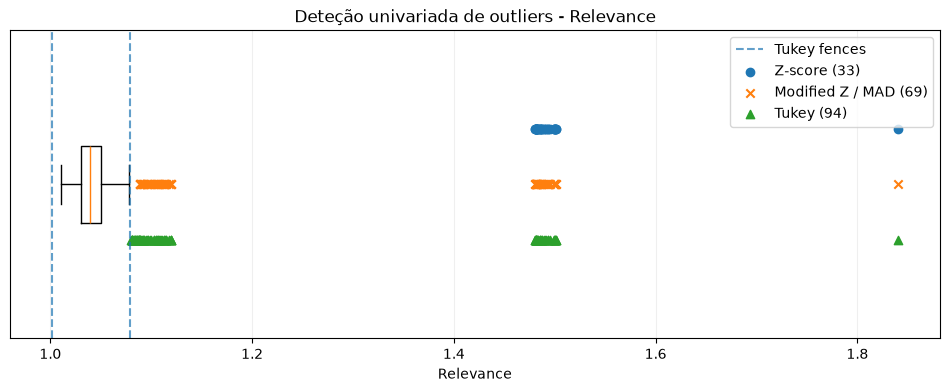

C:\Users\Alicia\AppData\Local\Temp\ipykernel_4184\3594875534.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


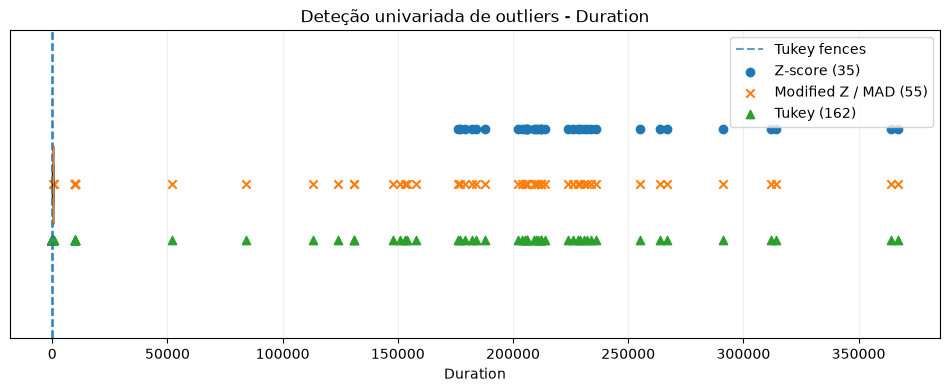

In [10]:
# 4.4.1 - Visualização dos outliers pelos três métodos

for col in continuous_cols:
    x = train[col].dropna()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    z_values = x[np.abs(z) > 3]

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad
    modified_z = (x - median) / scaled_mad
    mad_values = x[np.abs(modified_z) > 3.5]

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    tukey_values = x[(x < lower) | (x > upper)]

    plt.figure(figsize=(12, 4))

    # Boxplot sem mostrar os outliers automáticos
    plt.boxplot(
        x,
        vert=False,
        showfliers=False,
        positions=[1],
        widths=0.25
    )

    # Limites de Tukey
    plt.axvline(
        lower,
        linestyle="--",
        alpha=0.7,
        label="Tukey fences"
    )
    plt.axvline(
        upper,
        linestyle="--",
        alpha=0.7
    )

    # Valores sinalizados por cada método
    plt.scatter(
        z_values,
        np.full(len(z_values), 1.18),
        marker="o",
        label=f"Z-score ({len(z_values)})"
    )

    plt.scatter(
        mad_values,
        np.full(len(mad_values), 1.00),
        marker="x",
        label=f"Modified Z / MAD ({len(mad_values)})"
    )

    plt.scatter(
        tukey_values,
        np.full(len(tukey_values), 0.82),
        marker="^",
        label=f"Tukey ({len(tukey_values)})"
    )

    plt.yticks([])
    plt.xlabel(col)
    plt.title(f"Deteção univariada de outliers - {col}")
    plt.legend()
    plt.grid(axis="x", alpha=0.2)
    plt.show()

In [11]:
# Investigar os valores extremos de Duration

duration_extremes = train[
    ["Audio_Song", "Artist", "Title", "Duration"]
].dropna(subset=["Duration"]).copy()

print("10 menores valores de Duration:")
display(
    duration_extremes
    .sort_values("Duration")
    .head(10)
)

print("\n20 maiores valores de Duration:")
display(
    duration_extremes
    .sort_values("Duration", ascending=False)
    .head(20)
)

print("\nQuantis de Duration:")
display(
    train["Duration"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
    )
)

10 menores valores de Duration:


,Audio_Song,Artist,Title,Duration
911,MT0012023721,Bell Biv DeVoe,Ghetto Booty,-1.0
622,MT0011924283,Al Green,"Oh, Pretty Woman",-1.0
32,MT0010310891,Slayer,Psychopathy Red,-1.0
440,MT0010702898,Frank Sinatra,I'm Getting Sentimental Over You,-1.0
875,MT0004844832,Megadeth,Dread and the Fugitive Mind,-1.0
883,MT0010777106,Doris Day,That Jane from Maine,-1.0
108,MT0036368550,Taio Cruz,Dynamite,-1.0
104,MT0002277261,Wolf Parade,Dinner Bells,-1.0
657,MT0001639011,Ace of Base,Beautiful Life,-1.0
656,MT0008236217,queen,It's a Beautiful Day (Reprise),-1.0



20 maiores valores de Duration:


,Audio_Song,Artist,Title,Duration
216,MT0031834881,bob dylan,Summer Days,367000.0
697,MT0003496132,Rage Against the Machine,Wake Up,364000.0
96,MT0010363782,Maxwell,Know These Things: Shouldn't You,314000.0
819,MT0005023904,Einstï¿½rzende Neubauten,The Garden,312000.0
97,MT0002510318,Mï¿½m,Green Grass of Tunnel,291000.0
89,MT0000829765,Trisha Yearwood,When a Love Song Sings the Blues,267000.0
98,MT0014790813,Fat Joe,Pop U,264000.0
700,MT0028372740,Prince,Dirty Mind,255000.0
902,MT0026790435,Chingy,I Like That,236000.0
252,MT0004869271,Joni Mitchell,This Place,234000.0



Quantis de Duration:


0.00        -1.0
0.01        -1.0
0.05         0.0
0.25       154.0
0.50       197.0
0.75       249.0
0.90       346.0
0.95    153600.0
0.99    249680.0
1.00    367000.0
Name: Duration, dtype: float64

In [12]:
# Diagnóstico da possível mistura de unidades em Duration

duration = train["Duration"].dropna()

print("Total de valores válidos:", len(duration))
print("Duration < 0:", (duration < 0).sum())
print("Duration == 0:", (duration == 0).sum())
print("0 < Duration <= 1000:", ((duration > 0) & (duration <= 1000)).sum())
print("Duration > 1000:", (duration > 1000).sum())

print("\nValores > 1000 antes e depois de dividir por 1000:")

duration_unit_check = (
    train.loc[
        train["Duration"] > 1000,
        ["Audio_Song", "Artist", "Title", "Duration"]
    ]
    .copy()
)

duration_unit_check["Duration_div_1000"] = (
    duration_unit_check["Duration"] / 1000
)

display(duration_unit_check.head(20))

print("\nResumo após conversão apenas para diagnóstico:")
display(duration_unit_check["Duration_div_1000"].describe())

Total de valores válidos: 729
Duration < 0: 21
Duration == 0: 60
0 < Duration <= 1000: 595
Duration > 1000: 53

Valores > 1000 antes e depois de dividir por 1000:


,Audio_Song,Artist,Title,Duration,Duration_div_1000
10,MT0015541501,The Jam,'A' Bomb in Wardour Street,154000.0,154.000
23,MT0010630017,Mark Chesnutt,This Heartache Never Sleeps,228000.0,228.000
25,MT0005951020,Spoon,Mountain to Sound,229000.0,229.000
27,MT0002585767,The Davis Sisters,I Forgot More Than You'll Ever Know,179000.0,179.000
79,A085-69,The Cranberries,Dying in the Sun,212000.0,212.000
86,MT0002951872,Elvis Costello,Wonder Woman,188000.0,188.000
89,MT0000829765,Trisha Yearwood,When a Love Song Sings the Blues,267000.0,267.000
96,MT0010363782,Maxwell,Know These Things: Shouldn't You,314000.0,314.000
97,MT0002510318,Mï¿½m,Green Grass of Tunnel,291000.0,291.000
98,MT0014790813,Fat Joe,Pop U,264000.0,264.000



Resumo após conversão apenas para diagnóstico:


count     53.000000
mean     179.962132
std       88.982097
min        9.999000
25%      148.000000
50%      205.000000
75%      228.000000
max      367.000000
Name: Duration_div_1000, dtype: float64

In [13]:
# Verificar casos problemáticos antes de definir a regra de correção

duration_diagnostic = train[
    ["Audio_Song", "Artist", "Title", "Duration"]
].dropna(subset=["Duration"]).copy()

duration_diagnostic["Duration_if_ms"] = np.where(
    duration_diagnostic["Duration"] > 1000,
    duration_diagnostic["Duration"] / 1000,
    duration_diagnostic["Duration"]
)

print("Contagem por situação:")
print("Duration < 0:",
      (duration_diagnostic["Duration"] < 0).sum())
print("Duration == 0:",
      (duration_diagnostic["Duration"] == 0).sum())
print("Duration > 1000:",
      (duration_diagnostic["Duration"] > 1000).sum())

print("\nValores que continuariam muito pequenos após a possível conversão:")
display(
    duration_diagnostic[
        duration_diagnostic["Duration_if_ms"] < 30
    ].sort_values("Duration_if_ms")
)

print("\nValores que continuariam muito grandes após a possível conversão:")
display(
    duration_diagnostic[
        duration_diagnostic["Duration_if_ms"] > 600
    ].sort_values("Duration_if_ms", ascending=False)
)

Contagem por situação:
Duration < 0: 21
Duration == 0: 60
Duration > 1000: 53

Valores que continuariam muito pequenos após a possível conversão:


,Audio_Song,Artist,Title,Duration,Duration_if_ms
32,MT0010310891,Slayer,Psychopathy Red,-1.0,-1.000
108,MT0036368550,Taio Cruz,Dynamite,-1.0,-1.000
104,MT0002277261,Wolf Parade,Dinner Bells,-1.0,-1.000
80,MT0004890000,Al Green,Be My Baby,-1.0,-1.000
192,MT0002810052,Megadeth,Victory,-1.0,-1.000
...,...,...,...,...,...
317,MT0003669917,Third Day,Come Together,9999.0,9.999
382,MT0000811743,Buck Owens,My Last Chance With You,9999.0,9.999
662,MT0030248025,Liza Minnelli,Cabaret,9999.0,9.999
788,MT0004550434,SNFU,Don't Have the Cow,9999.0,9.999



Valores que continuariam muito grandes após a possível conversão:


,Audio_Song,Artist,Title,Duration,Duration_if_ms
755,MT0001435061,Michael Bloomfield,It's My Own Fault,656.0,656.0


In [14]:
# Examinar os padrões suspeitos de Duration

print("Valores originais de Duration <= 30:")
display(
    train.loc[
        train["Duration"].notna() & (train["Duration"] <= 30),
        "Duration"
    ].value_counts().sort_index()
)

print("\nValores entre 1000 e 10000:")
display(
    train.loc[
        train["Duration"].between(1000, 10000, inclusive="both"),
        "Duration"
    ].value_counts().sort_index()
)

print("\nQuantidade de valores > 10000:")
print((train["Duration"] > 10000).sum())

print("\nResumo dos valores > 10000 depois de dividir por 1000:")
display(
    (train.loc[train["Duration"] > 10000, "Duration"] / 1000)
    .describe()
)

Valores originais de Duration <= 30:


Duration
-1.00    21
 0.00    60
 2.52     1
 2.72     1
 3.12     1
 3.40     1
 3.50     1
 3.57     1
 3.75     1
 3.82     1
 3.85     1
 3.87     1
 4.02     1
 4.20     1
 4.33     1
 4.42     1
 5.30     1
 5.75     1
 5.93     1
 6.47     1
Name: count, dtype: int64


Valores entre 1000 e 10000:


Duration
9999.0    7
Name: count, dtype: int64


Quantidade de valores > 10000:
46

Resumo dos valores > 10000 depois de dividir por 1000:


count     46.000000
mean     205.826087
std       63.024265
min       52.000000
25%      176.250000
50%      207.500000
75%      230.500000
max      367.000000
Name: Duration, dtype: float64

In [15]:
# Verificar se valores positivos abaixo de 30 estão em minutos

duration_minutes = train.loc[
    (train["Duration"] > 0) & (train["Duration"] < 30),
    ["Audio_Song", "Artist", "Title", "Duration"]
].copy()

duration_minutes["Duration_x60"] = duration_minutes["Duration"] * 60

print("Quantidade de valores positivos abaixo de 30:")
print(len(duration_minutes))

print("\nPossíveis durações em minutos convertidas para segundos:")
display(duration_minutes)

print("\nResumo após multiplicar por 60:")
display(duration_minutes["Duration_x60"].describe())

Quantidade de valores positivos abaixo de 30:
18

Possíveis durações em minutos convertidas para segundos:


,Audio_Song,Artist,Title,Duration,Duration_x60
33,MT0013881862,Donots,Time's Up,3.40,204.0
107,MT0013464231,Mary J. Blige,Love @ 1st Sight,5.30,318.0
190,MT0033459750,Donovan,Epistle to Derroll,5.75,345.0
215,MT0000829531,Ice Cube,Steady Mobbin',4.20,252.0
397,MT0015005100,Ella Fitzgerald,Too Darn Hot,3.50,210.0
417,MT0012933678,Marc Anthony,The Mexican 2002,4.33,259.8
420,MT0001152664,Radiohead,How to Disappear Completely,5.93,355.8
459,MT0004540242,Huey Lewis,Cruisin',3.57,214.2
488,MT0002580064,Johnny Winter,Early in the Morning,3.82,229.2
552,MT0000271454,Ray Charles,"What'd I Say, Pts. 1 & 2",6.47,388.2



Resumo após multiplicar por 60:


count     18.000000
mean     248.466667
std       65.205882
min      151.200000
25%      211.050000
50%      231.600000
75%      263.850000
max      388.200000
Name: Duration_x60, dtype: float64

### 4.4.1 Deteção univariada de outliers

Foram comparados três métodos: z-score, modified z-score (MAD) e limites de Tukey.

Em `Relevance`, foram identificados 33, 69 e 94 outliers, respetivamente. Em `Duration`, foram identificados 35, 55 e 162.

A maior diferença ocorreu em `Duration`, devido à presença de valores em diferentes escalas e possíveis valores inválidos, como `-1`, `0` e `9999`. Estes extremos afetam a média e o desvio-padrão, tornando o z-score mais suscetível ao efeito de *masking*. Por isso, MAD e Tukey mostraram-se mais adequados neste caso.

Os valores sinalizados foram considerados candidatos a investigação e não removidos automaticamente, pois um outlier pode representar um erro ou um valor extremo legítimo.

### 4.4.2 Deteção multivariada de outliers

In [17]:
# 4.4.2 - Preparação do espaço numérico

from sklearn.preprocessing import RobustScaler

multivariate_cols = ["Relevance", "Duration"]

# Apenas registos com ambas as variáveis disponíveis
X = train[multivariate_cols].dropna().copy()

# Escalonamento robusto baseado na mediana e no IQR
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print("Variáveis utilizadas:", multivariate_cols)
print("Registos disponíveis:", len(X))
print("Dimensão do espaço numérico:", X_scaled.shape)

display(X.describe().T)

Variáveis utilizadas: ['Relevance', 'Duration']
Registos disponíveis: 623
Dimensão do espaço numérico: (623, 2)


,count,mean,std,min,25%,50%,75%,max
Relevance,623.0,1.063016,0.096351,1.010274,1.030307,1.038807,1.049766,1.501121
Duration,623.0,12830.805698,51974.179437,-1.000000,152.500000,194.000000,246.500000,367000.000000


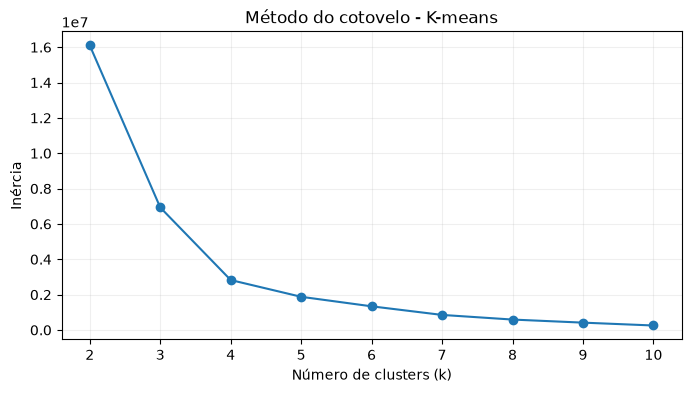

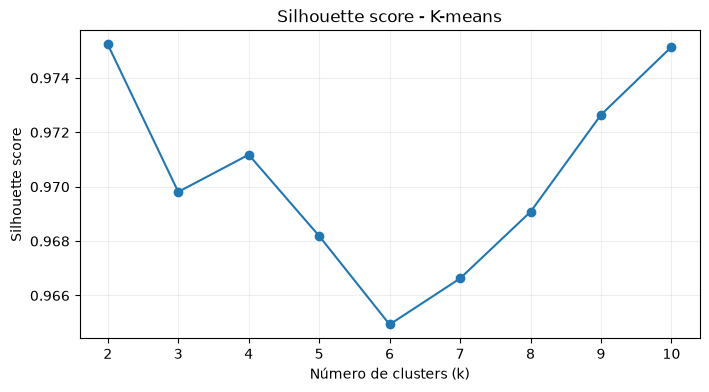

,k,Inércia,Silhouette
0,2,1.609561e+07,0.975229
1,3,6.932299e+06,0.969809
2,4,2.826750e+06,0.971177
3,5,1.878201e+06,0.968187
4,6,1.339397e+06,0.964933
5,7,8.530203e+05,0.966626
6,8,5.905973e+05,0.969076
7,9,4.165806e+05,0.972644
8,10,2.546153e+05,0.975140


In [18]:
# Escolha do número de clusters para K-means

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Curva do cotovelo
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo - K-means")
plt.grid(alpha=0.2)
plt.show()

# Silhouette
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score - K-means")
plt.grid(alpha=0.2)
plt.show()

# Valores numéricos
k_evaluation = pd.DataFrame({
    "k": list(k_values),
    "Inércia": inertias,
    "Silhouette": silhouette_scores
})

display(k_evaluation)

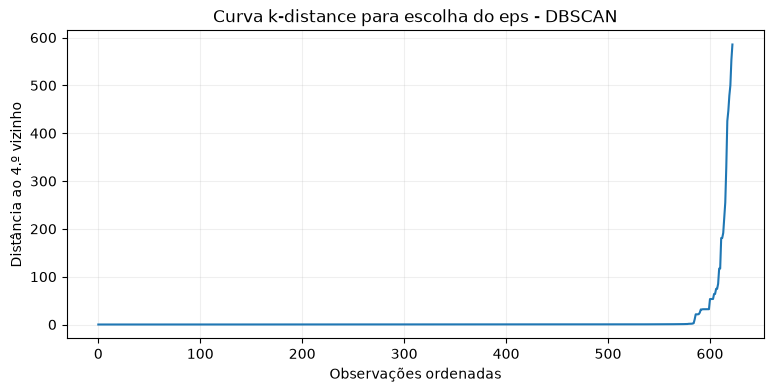

20 maiores distâncias ao 4.º vizinho:


,Distância
622,585.576352
621,553.192061
620,500.000226
619,478.723479
618,446.819249
617,425.533042
616,329.787817
615,255.319597
614,223.404402
613,191.491884


In [19]:
# Escolha do eps para DBSCAN através da distância ao 4.º vizinho

from sklearn.neighbors import NearestNeighbors

min_samples = 4

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

# Distância ao 4.º vizinho mais próximo
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance para escolha do eps - DBSCAN")
plt.grid(alpha=0.2)
plt.show()

# Mostrar as maiores distâncias para facilitar a escolha
print("20 maiores distâncias ao 4.º vizinho:")
display(
    pd.Series(k_distances)
    .sort_values(ascending=False)
    .head(20)
    .to_frame("Distância")
)

Quantis das distâncias ao 4.º vizinho:


0.50      0.106849
0.75      0.221121
0.90      0.559366
0.95     30.804218
0.97     56.933849
0.98    117.024618
0.99    313.404808
dtype: float64

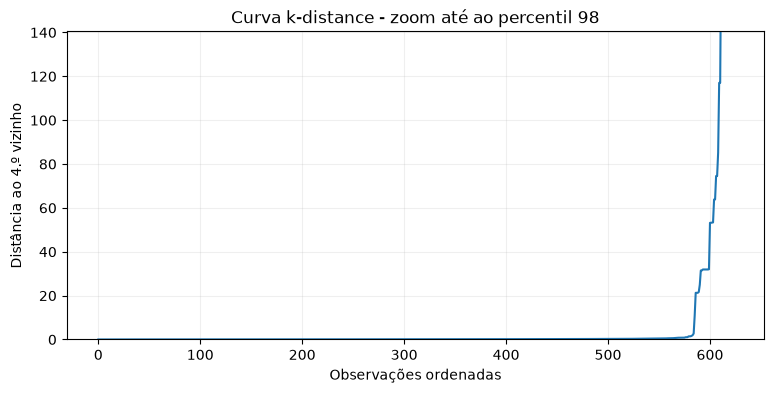

In [20]:
# Ampliar a região relevante da curva k-distance

print("Quantis das distâncias ao 4.º vizinho:")
display(
    pd.Series(k_distances).quantile(
        [0.50, 0.75, 0.90, 0.95, 0.97, 0.98, 0.99]
    )
)

# Zoom excluindo visualmente os extremos muito distantes
limit_98 = np.quantile(k_distances, 0.98)

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0, limit_98 * 1.2)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - zoom até ao percentil 98")
plt.grid(alpha=0.2)
plt.show()

,Percentil,Distância
0,0.900,0.559366
1,0.905,0.602648
2,0.910,0.722725
3,0.915,0.800162
4,0.920,0.823388
5,0.925,0.903224
6,0.930,1.228348
7,0.935,1.581662
8,0.940,8.289085
9,0.945,21.285754


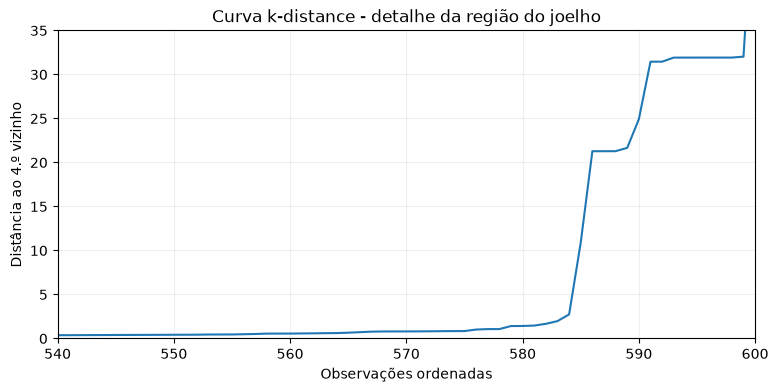

In [21]:
# Zoom detalhado na região do joelho da curva k-distance

quantiles_detail = np.arange(0.90, 0.951, 0.005)

detail = pd.DataFrame({
    "Percentil": quantiles_detail,
    "Distância": [
        np.quantile(k_distances, q)
        for q in quantiles_detail
    ]
})

display(detail)

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.xlim(540, 600)
plt.ylim(0, 35)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - detalhe da região do joelho")
plt.grid(alpha=0.2)
plt.show()

In [22]:
# Aplicação de K-means e DBSCAN

from sklearn.cluster import KMeans, DBSCAN

# K-means com k escolhido pelo método do cotovelo
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# DBSCAN com parâmetros definidos pela curva k-distance
dbscan = DBSCAN(
    eps=2.0,
    min_samples=4
)

dbscan_labels = dbscan.fit_predict(X_scaled)

# Guardar resultados
multivariate_results = X.copy()
multivariate_results["KMeans_cluster"] = kmeans_labels
multivariate_results["DBSCAN_cluster"] = dbscan_labels

print("Tamanho dos clusters do K-means:")
display(
    multivariate_results["KMeans_cluster"]
    .value_counts()
    .sort_index()
)

print("\nTamanho dos clusters do DBSCAN:")
display(
    multivariate_results["DBSCAN_cluster"]
    .value_counts()
    .sort_index()
)

print("\nRegistos classificados como ruído pelo DBSCAN:")
print((dbscan_labels == -1).sum())

Tamanho dos clusters do K-means:


KMeans_cluster
0    586
1     23
2      9
3      5
Name: count, dtype: int64


Tamanho dos clusters do DBSCAN:


DBSCAN_cluster
-1     39
 0    550
 1     27
 2      7
Name: count, dtype: int64


Registos classificados como ruído pelo DBSCAN:
39


Candidatos sinalizados pelo K-means: 32
Candidatos sinalizados pelo DBSCAN: 39
Sinalizados pelos dois métodos: 27


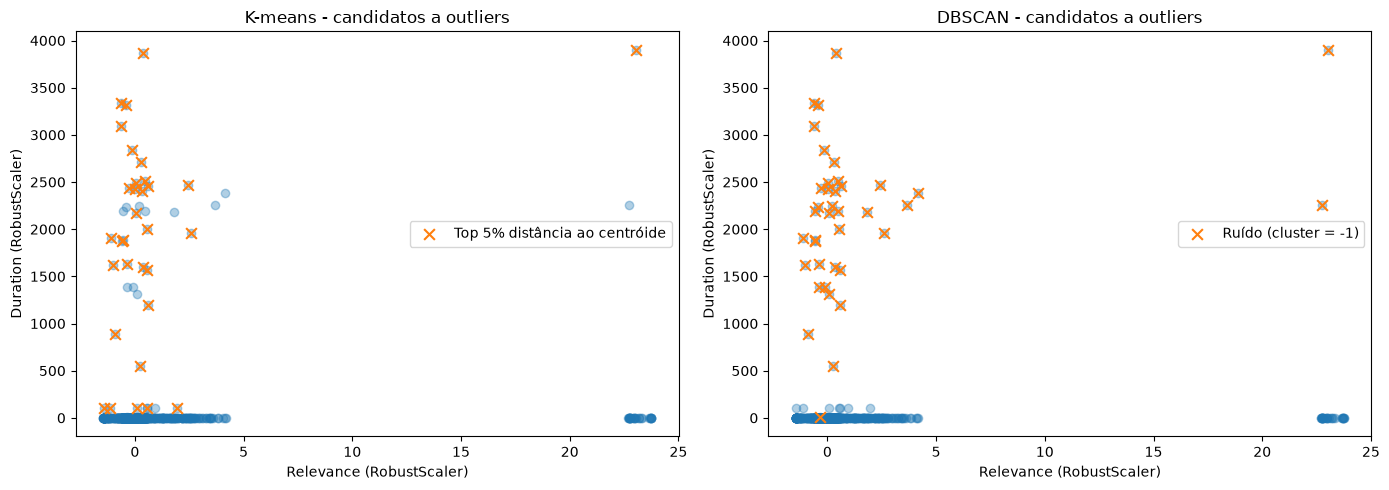

In [23]:
# Comparação visual entre K-means e DBSCAN

# Distância de cada registo ao centróide do seu cluster K-means
kmeans_distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[kmeans_labels],
    axis=1
)

# Top 5% das maiores distâncias como candidatos a outliers
kmeans_threshold = np.quantile(kmeans_distances, 0.95)
kmeans_outliers = kmeans_distances >= kmeans_threshold

# Ruído do DBSCAN
dbscan_outliers = dbscan_labels == -1

print("Candidatos sinalizados pelo K-means:",
      kmeans_outliers.sum())

print("Candidatos sinalizados pelo DBSCAN:",
      dbscan_outliers.sum())

print("Sinalizados pelos dois métodos:",
      (kmeans_outliers & dbscan_outliers).sum())

# Comparação lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-means
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    alpha=0.35
)

axes[0].scatter(
    X_scaled[kmeans_outliers, 0],
    X_scaled[kmeans_outliers, 1],
    marker="x",
    s=60,
    label="Top 5% distância ao centróide"
)

axes[0].set_title("K-means - candidatos a outliers")
axes[0].set_xlabel("Relevance (RobustScaler)")
axes[0].set_ylabel("Duration (RobustScaler)")
axes[0].legend()

# DBSCAN
axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    alpha=0.35
)

axes[1].scatter(
    X_scaled[dbscan_outliers, 0],
    X_scaled[dbscan_outliers, 1],
    marker="x",
    s=60,
    label="Ruído (cluster = -1)"
)

axes[1].set_title("DBSCAN - candidatos a outliers")
axes[1].set_xlabel("Relevance (RobustScaler)")
axes[1].set_ylabel("Duration (RobustScaler)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [24]:
# Comparação dos registos sinalizados por K-means e DBSCAN

comparison = train.loc[X.index, [
    "Audio_Song",
    "Artist",
    "Title",
    "Relevance",
    "Duration"
]].copy()

comparison["KMeans_cluster"] = kmeans_labels
comparison["KMeans_distance"] = kmeans_distances
comparison["KMeans_outlier"] = kmeans_outliers

comparison["DBSCAN_cluster"] = dbscan_labels
comparison["DBSCAN_outlier"] = dbscan_outliers

# Encontrados apenas pelo K-means
only_kmeans = comparison[
    comparison["KMeans_outlier"] &
    ~comparison["DBSCAN_outlier"]
].sort_values("KMeans_distance", ascending=False)

# Encontrados apenas pelo DBSCAN
only_dbscan = comparison[
    ~comparison["KMeans_outlier"] &
    comparison["DBSCAN_outlier"]
].sort_values("KMeans_distance", ascending=False)

print("Sinalizados apenas pelo K-means:")
display(only_kmeans)

print("\nSinalizados apenas pelo DBSCAN:")
display(only_dbscan)

Sinalizados apenas pelo K-means:


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier
382,MT0000811743,Buck Owens,My Last Chance With You,1.010870,9999.0,0,102.329669,True,2,False
788,MT0004550434,SNFU,Don't Have the Cow,1.016864,9999.0,0,102.322123,True,2,False
243,MT0014936205,The Drifters,There Goes My Baby,1.040531,9999.0,0,102.301387,True,2,False
317,MT0003669917,Third Day,Come Together,1.076848,9999.0,0,102.297683,True,2,False
525,MT0008794071,bing crosby,First Noel,1.049315,9999.0,0,102.297370,True,2,False



Sinalizados apenas pelo DBSCAN:


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier
465,MT0008105399,Toby Keith,If I Was Jesus [Live],1.119855,224000.0,1,101.790007,False,-1,True
258,MT0026682960,Fats Domino,Your Cheatin' Heart,1.074180,205000.0,1,100.370269,False,-1,True
206,MT0001115644,Doug Stone,Gone Out of My Mind,1.027772,206000.0,1,89.757845,False,-1,True
640,MT0008966305,David Guetta,Sexy 17,1.047998,206000.0,1,89.738789,False,-1,True
849,MT0000197431,Connie Francis,Plenty Good Lovin',1.040357,124000.0,2,86.288671,False,-1,True
191,MT0012317309,BIG BILL BROONZY,Worrying My Mind,1.030536,210000.0,1,47.221890,False,-1,True
125,MT0034410340,John Lee Hooker,No Rollin' Blues,1.042727,211000.0,1,36.566916,False,-1,True
475,MT0027149420,jennifer lopez,Play,1.481410,212000.0,1,33.438260,False,-1,True
207,MT0001566152,Willie Nelson,Blue Hotel,1.110075,212000.0,1,25.984091,False,-1,True
528,MT0034549623,Jim Reeves,WHEN TWO WORLD COLLIDES,1.031309,131000.0,2,11.823089,False,-1,True


In [25]:
# Procurar registos encontrados pelo DBSCAN,
# mas não sinalizados por nenhum método univariado

def univariate_flags(series):
    x = series.dropna()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    flag_z = np.abs(z) > 3

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        flag_mad = np.abs(modified_z) > 3.5
    else:
        flag_mad = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    flag_tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    return flag_z, flag_mad, flag_tukey


# Calcular flags para Relevance e Duration
flags = pd.DataFrame(index=X.index)

for col in ["Relevance", "Duration"]:
    z, mad, tukey = univariate_flags(train[col])

    flags.loc[z.index, f"{col}_Z"] = z
    flags.loc[mad.index, f"{col}_MAD"] = mad
    flags.loc[tukey.index, f"{col}_Tukey"] = tukey

flags = flags.fillna(False).astype(bool)

# Verdadeiro se qualquer método univariado sinalizou o registo
flags["Qualquer_univariado"] = flags.any(axis=1)

# Ruído DBSCAN que passou por todos os métodos univariados
candidate_444 = comparison.loc[
    dbscan_outliers & ~flags["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN não detetados por nenhum método univariado:")
print(len(candidate_444))

display(candidate_444)

KeyError: '[4, 7, 14, 18, 29, 34, 35, 39, 44, 46, 49, 66, 73, 84, 90, 94, 100, 114, 116, 128, 129, 135, 136, 146, 148, 151, 161, 162, 164, 169, 188, 198, 212, 214, 219, 229, 231, 234, 235, 262, 269, 270, 274, 290, 297, 302, 307, 314, 320, 326, 336, 340, 354, 357, 369, 374, 375, 391, 396, 411, 423, 425, 426, 427, 470, 483, 492, 498, 499, 502, 503, 523, 527, 533, 542, 544, 560, 562, 568, 569, 572, 581, 583, 586, 587, 590, 591, 593, 596, 598, 601, 609, 621, 632, 634, 639, 649, 658, 661, 666, 674, 687, 692, 705, 717, 735, 738, 751, 760, 786, 789, 794, 795, 801, 804, 813, 814, 821, 824, 834, 844, 848, 851, 863, 865, 869, 879, 880, 884, 887, 889, 909, 910] not in index'

In [26]:
# Procurar registos encontrados pelo DBSCAN,
# mas não sinalizados por nenhum método univariado

def univariate_flags(series):
    # Aqui os dados já pertencem ao mesmo conjunto X
    x = series.copy()

    # Z-score
    z = (x - x.mean()) / x.std(ddof=1)
    flag_z = np.abs(z) > 3

    # Modified Z-score (MAD)
    median = x.median()
    mad = np.median(np.abs(x - median))
    scaled_mad = 1.4826 * mad

    if scaled_mad > 0:
        modified_z = (x - median) / scaled_mad
        flag_mad = np.abs(modified_z) > 3.5
    else:
        flag_mad = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    flag_tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    return flag_z, flag_mad, flag_tukey


# DataFrame com exatamente os mesmos índices de X
flags = pd.DataFrame(index=X.index)

for col in ["Relevance", "Duration"]:
    z, mad, tukey = univariate_flags(X[col])

    flags[f"{col}_Z"] = z
    flags[f"{col}_MAD"] = mad
    flags[f"{col}_Tukey"] = tukey

# Foi sinalizado por pelo menos um método univariado?
flags["Qualquer_univariado"] = flags.any(axis=1)

# Converter o resultado do DBSCAN para Series com o mesmo índice
dbscan_outlier_series = pd.Series(
    dbscan_outliers,
    index=X.index
)

# DBSCAN encontrou, mas nenhum método univariado encontrou
candidate_444 = comparison.loc[
    dbscan_outlier_series & ~flags["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN não detetados por nenhum método univariado:")
print(len(candidate_444))

display(candidate_444)

Ruídos do DBSCAN não detetados por nenhum método univariado:
0


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier


In [27]:
# 4.4.4 - Procurar registos detetados pelo K-means,
# mas não detetados pelos métodos univariados

candidate_kmeans_444 = comparison.loc[
    comparison["KMeans_outlier"] & ~flags["Qualquer_univariado"]
].copy()

print("Outliers do K-means não detetados por nenhum método univariado:")
print(len(candidate_kmeans_444))

display(candidate_kmeans_444)

Outliers do K-means não detetados por nenhum método univariado:
0


,Audio_Song,Artist,Title,Relevance,Duration,KMeans_cluster,KMeans_distance,KMeans_outlier,DBSCAN_cluster,DBSCAN_outlier


In [28]:
from sklearn.cluster import DBSCAN

# Testar diferentes valores de eps próximos do joelho da curva k-distance
eps_values = [1.0, 1.5, 2.0, 3.0, 5.0, 10.0, 20.0]

resultados_eps = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=4).fit_predict(X_scaled)

    ruido = labels == -1

    ruido_series = pd.Series(
        ruido,
        index=X.index
    )

    # Ruídos que NÃO foram encontrados pelos métodos univariados
    apenas_multivariado = ruido_series & ~flags["Qualquer_univariado"]

    resultados_eps.append({
        "eps": eps,
        "N_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "Ruídos": int(ruido.sum()),
        "Só multivariado": int(apenas_multivariado.sum())
    })

display(pd.DataFrame(resultados_eps))

,eps,N_clusters,Ruídos,Só multivariado
0,1.0,3,43,0
1,1.5,3,40,0
2,2.0,3,39,0
3,3.0,3,38,0
4,5.0,3,38,0
5,10.0,3,38,0
6,20.0,3,34,0


In [29]:
# Criar uma versão corrigida de Duration apenas para a análise multivariada

train_mv = train.copy()

def corrigir_duration(valor):
    if pd.isna(valor):
        return np.nan

    # Valores inválidos ou sentinelas
    if valor in [-1, 0, 9999]:
        return np.nan

    # Valores aparentemente armazenados em milissegundos
    if valor > 10000:
        return valor / 1000

    # Valores muito pequenos aparentemente armazenados em minutos
    if 0 < valor < 10:
        return valor * 60

    # Restantes já parecem estar em segundos
    return valor

train_mv["Duration_corrigida"] = train_mv["Duration"].apply(corrigir_duration)

print("Duration original:")
display(train["Duration"].describe())

print("\nDuration corrigida para análise:")
display(train_mv["Duration_corrigida"].describe())

Duration original:


count       729.000000
mean      13251.723649
std       52417.043040
min          -1.000000
25%         154.000000
50%         197.000000
75%         249.000000
max      367000.000000
Name: Duration, dtype: float64


Duration corrigida para análise:


count    641.000000
mean     212.793136
std       63.351404
min       48.000000
25%      170.000000
50%      205.000000
75%      241.000000
max      656.000000
Name: Duration_corrigida, dtype: float64

In [30]:
# Novo espaço multivariado com Duration corrigida

X_mv = train_mv[["Relevance", "Duration_corrigida"]].dropna().copy()

scaler_mv = RobustScaler()
X_mv_scaled = scaler_mv.fit_transform(X_mv)

print("Registos disponíveis:", len(X_mv))

print("\nResumo das variáveis:")
display(X_mv.describe().T)

Registos disponíveis: 540

Resumo das variáveis:


,count,mean,std,min,25%,50%,75%,max
Relevance,540.0,1.061439,0.092572,1.010274,1.030333,1.038653,1.049512,1.501121
Duration_corrigida,540.0,211.831481,62.852400,48.000000,169.000000,204.000000,242.000000,656.000000


In [31]:
# Procurar anomalias exclusivamente multivariadas no espaço corrigido

from sklearn.cluster import DBSCAN

# DBSCAN no espaço corrigido
dbscan_mv = DBSCAN(eps=1.5, min_samples=4)
labels_mv = dbscan_mv.fit_predict(X_mv_scaled)

dbscan_noise_mv = pd.Series(
    labels_mv == -1,
    index=X_mv.index
)

# Criar flags univariadas no MESMO espaço corrigido
flags_mv = pd.DataFrame(index=X_mv.index)

for col in ["Relevance", "Duration_corrigida"]:
    x = X_mv[col]

    # Z-score
    z = np.abs((x - x.mean()) / x.std()) > 3

    # Modified Z / MAD
    mediana = x.median()
    mad = np.median(np.abs(x - mediana))
    mad_flag = np.abs((x - mediana) / (1.4826 * mad)) > 3.5

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    tukey = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    flags_mv[f"{col}_qualquer"] = z | mad_flag | tukey

flags_mv["Qualquer_univariado"] = flags_mv.any(axis=1)

# DBSCAN encontrou, mas nenhum método univariado encontrou
candidate_444_mv = X_mv.loc[
    dbscan_noise_mv & ~flags_mv["Qualquer_univariado"]
].copy()

print("Ruídos do DBSCAN:", int(dbscan_noise_mv.sum()))
print(
    "Ruídos não detetados por nenhum método univariado:",
    len(candidate_444_mv)
)

display(candidate_444_mv)

Ruídos do DBSCAN: 2
Ruídos não detetados por nenhum método univariado: 0


,Relevance,Duration_corrigida


In [32]:
print("Train atualmente utilizado:")
print(train.shape)

print("\nFicheiros CSV disponíveis nesta pasta e subpastas:")

import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

Train atualmente utilizado:
(913, 27)

Ficheiros CSV disponíveis nesta pasta e subpastas:
.\cleaned\test_clean.csv
.\cleaned\train_clean.csv
.\merge_ecac\av_values.csv
.\merge_ecac\metadata.csv
.\merge_ecac\test_songs.csv
.\merge_original\av_values.csv
.\merge_original\metadata.csv
.\truth\truth_cells.csv
.\truth\truth_rows.csv


In [33]:
# Verificar os datasets danificados originais, antes da limpeza

metadata_raw = pd.read_csv("merge_ecac/metadata.csv")
av_raw = pd.read_csv("merge_ecac/av_values.csv")
test_songs_raw = pd.read_csv("merge_ecac/test_songs.csv")

print("metadata.csv:", metadata_raw.shape)
print("av_values.csv:", av_raw.shape)
print("test_songs.csv:", test_songs_raw.shape)

print("\nColunas de metadata.csv:")
print(metadata_raw.columns.tolist())

print("\nColunas de av_values.csv:")
print(av_raw.columns.tolist())

print("\nColunas de test_songs.csv:")
print(test_songs_raw.columns.tolist())

metadata.csv: (1348, 27)
av_values.csv: (1323, 4)
test_songs.csv: (409, 2)

Colunas de metadata.csv:
['Audio_Song', 'Lyric_Song', 'Quadrant', 'AllMusic Id', 'AllMusic Extraction Date', 'Artist', 'Title', 'Relevance', 'Year', 'LowestYear', 'Duration', 'Moods', 'MoodsAll', 'MoodsAllWeights', 'Genres', 'GenreWeights', 'Themes', 'ThemeWeights', 'Styles', 'StyleWeights', 'AppearancesTrackIDs', 'AppearancesAlbumIDs', 'Sample', 'SampleURL', 'ActualYear', 'num_Genres', 'num_MoodsAll']

Colunas de av_values.csv:
['Audio_Song', 'Lyric_Song', 'Arousal', 'Valence']

Colunas de test_songs.csv:
['Audio_Song', 'Quadrant']


In [34]:
# Inspecionar Arousal e Valence antes da limpeza

print("Tipos das colunas:")
print(av_raw.dtypes)

print("\nResumo estatístico:")
display(av_raw[["Arousal", "Valence"]].describe().T)

print("\nValores ausentes:")
print(av_raw[["Arousal", "Valence"]].isna().sum())

# Identificar músicas pertencentes ao teste
test_ids = set(test_songs_raw["Audio_Song"])

av_train_raw = av_raw[
    ~av_raw["Audio_Song"].isin(test_ids)
].copy()

av_test_raw = av_raw[
    av_raw["Audio_Song"].isin(test_ids)
].copy()

print("\nAV treino:", av_train_raw.shape)
print("AV teste:", av_test_raw.shape)

Tipos das colunas:
Audio_Song        str
Lyric_Song        str
Arousal       float64
Valence       float64
dtype: object

Resumo estatístico:


,count,mean,std,min,25%,50%,75%,max
Arousal,1323.0,0.491791,0.146581,0.0625,0.36625,0.51125,0.60000,0.9750
Valence,1323.0,0.522637,0.244512,0.0750,0.28625,0.49375,0.77375,0.9875



Valores ausentes:
Arousal    0
Valence    0
dtype: int64

AV treino: (914, 4)
AV teste: (409, 4)


In [35]:
# Alinhar Arousal e Valence com o conjunto de treino já limpo

av_train = av_train_raw[
    av_train_raw["Audio_Song"].isin(train["Audio_Song"])
].copy()

# Verificar qual registo ficou de fora
av_removidos = av_train_raw[
    ~av_train_raw["Audio_Song"].isin(train["Audio_Song"])
]

print("AV treino original:", av_train_raw.shape)
print("AV treino após alinhamento:", av_train.shape)

print("\nRegisto presente no AV, mas já removido do train:")
display(av_removidos)

AV treino original: (914, 4)
AV treino após alinhamento: (913, 4)

Registo presente no AV, mas já removido do train:


,Audio_Song,Lyric_Song,Arousal,Valence
474,MT0003503243,MT0003503243,0.54375,0.2675


In [36]:
# 4.4.4 - Deteção univariada em Arousal e Valence

flags_av = pd.DataFrame(index=av_train.index)

for col in ["Arousal", "Valence"]:
    x = av_train[col]

    # Z-score
    z = np.abs((x - x.mean()) / x.std(ddof=1)) > 3

    # Modified z-score baseado no MAD
    mediana = x.median()
    mad = np.median(np.abs(x - mediana))

    if mad > 0:
        mad_flag = np.abs(
            (x - mediana) / (1.4826 * mad)
        ) > 3.5
    else:
        mad_flag = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    tukey = (
        (x < q1 - 1.5 * iqr) |
        (x > q3 + 1.5 * iqr)
    )

    flags_av[f"{col}_Z"] = z
    flags_av[f"{col}_MAD"] = mad_flag
    flags_av[f"{col}_Tukey"] = tukey

flags_av["Qualquer_univariado"] = flags_av.any(axis=1)

print("Outliers por critério:")
print(flags_av.sum())

print(
    "\nRegistos sem qualquer sinalização univariada:",
    (~flags_av["Qualquer_univariado"]).sum()
)

Outliers por critério:
Arousal_Z              1
Arousal_MAD            0
Arousal_Tukey          1
Valence_Z              0
Valence_MAD            0
Valence_Tukey          0
Qualquer_univariado    1
dtype: int64

Registos sem qualquer sinalização univariada: 912


Percentis da distância ao 4.º vizinho:
0.90: 0.0828
0.92: 0.0932
0.94: 0.1004
0.95: 0.1111
0.96: 0.1245
0.97: 0.1426
0.98: 0.1831
0.99: 0.2448


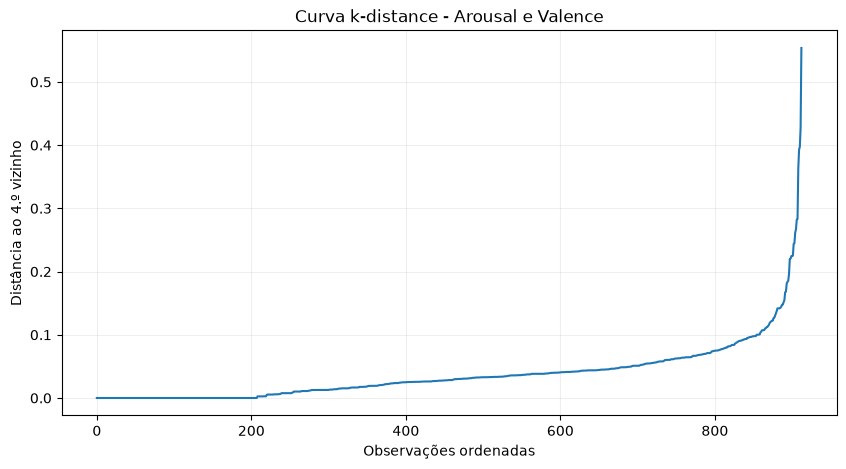

In [37]:
# 4.4.4 - Curva k-distance para Arousal e Valence

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors

# Espaço multivariado
X_av = av_train[["Arousal", "Valence"]].copy()

# Escalonamento robusto
scaler_av = RobustScaler()
X_av_scaled = scaler_av.fit_transform(X_av)

# min_samples = 4 -> distância ao 4.º vizinho
min_samples_av = 4

neighbors_av = NearestNeighbors(n_neighbors=min_samples_av)
neighbors_av.fit(X_av_scaled)

distances_av, _ = neighbors_av.kneighbors(X_av_scaled)

# Distância ao 4.º vizinho, ordenada
k_dist_av = np.sort(distances_av[:, -1])

# Mostrar percentis para ajudar na escolha do eps
percentis = [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]

print("Percentis da distância ao 4.º vizinho:")
for p in percentis:
    print(f"{p:.2f}: {np.quantile(k_dist_av, p):.4f}")

# Curva k-distance
plt.figure(figsize=(10, 5))
plt.plot(k_dist_av)
plt.xlabel("Observações ordenadas")
plt.ylabel("Distância ao 4.º vizinho")
plt.title("Curva k-distance - Arousal e Valence")
plt.grid(alpha=0.2)
plt.show()

In [38]:
# Testar valores de eps na região do joelho

from sklearn.cluster import DBSCAN

resultados_eps_av = []

for eps in [0.10, 0.12, 0.14, 0.16, 0.18, 0.20]:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=4
    )
    
    labels = dbscan.fit_predict(X_av_scaled)
    ruido = labels == -1
    
    # Converter para Series com o mesmo índice
    ruido_series = pd.Series(
        ruido,
        index=X_av.index
    )
    
    apenas_multivariado = (
        ruido_series &
        ~flags_av["Qualquer_univariado"]
    )
    
    resultados_eps_av.append({
        "eps": eps,
        "N_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "Ruídos": int(ruido.sum()),
        "Só_multivariado": int(apenas_multivariado.sum())
    })

resultados_eps_av = pd.DataFrame(resultados_eps_av)

display(resultados_eps_av)

,eps,N_clusters,Ruídos,Só_multivariado
0,0.10,9,43,42
1,0.12,4,31,30
2,0.14,4,18,17
3,0.16,3,15,14
4,0.18,3,14,13
5,0.20,3,13,12


In [40]:
# 4.4.4 - Identificar registos encontrados apenas pela análise multivariada

# Índices dos candidatos dentro de av_train
candidate_indices = only_multivariate[only_multivariate].index

# Obter Arousal, Valence e Audio_Song
candidatos_av = av_train.loc[
    candidate_indices,
    ["Audio_Song", "Arousal", "Valence"]
].copy()

# Juntar com os metadados usando Audio_Song como identificador
candidatos_444 = candidatos_av.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    on="Audio_Song",
    how="left"
)

# Organizar as colunas
candidatos_444 = candidatos_444[
    ["Audio_Song", "Artist", "Title",
     "Quadrant", "Arousal", "Valence"]
]

print("Número de candidatos ao 4.4.4:", len(candidatos_444))

display(
    candidatos_444.sort_values(
        ["Arousal", "Valence"]
    )
)

Número de candidatos ao 4.4.4: 13


,Audio_Song,Artist,Title,Quadrant,Arousal,Valence
10,A168,Enigma,The Voice of Enigma,Q4,0.06250,0.79375
1,A018,Tony Bennett,Solitude,Q3,0.13125,0.21875
5,A119-151,Ciaran McAuley (Lisa Gerrard),On an Ocean,Q4,0.14375,0.70625
3,A063-90,Vangelis,Albedo 0.39,Q4,0.15625,0.67500
9,A165,Amata,Water Song,Q4,0.18750,0.75000
12,MT0031893087,Lenny Kravitz,Let Love Rule,Q4,0.46500,0.57875
11,MT0007074655,Soulfly,Call to Arms,Q2,0.65000,0.26000
4,A101-111,Donna Summer,I Feel Love,Q1,0.77500,0.95625
7,A128-109,Beyoncï¿½,Single Ladies (Put a Ring On It),Q1,0.86250,0.71250
0,A014,Jamiroquai,Feels Just Like It Should,Q1,0.86250,0.72500


In [41]:
# 4.4.4 - Encontrar o candidato menos extremo individualmente

analise_444 = candidatos_444.copy()

# Percentil de cada valor dentro da distribuição completa
analise_444["Percentil_Arousal"] = analise_444["Arousal"].apply(
    lambda x: (av_train["Arousal"] <= x).mean()
)

analise_444["Percentil_Valence"] = analise_444["Valence"].apply(
    lambda x: (av_train["Valence"] <= x).mean()
)

# Distância de cada percentil ao centro da distribuição (0.5)
analise_444["Extremo_univariado"] = (
    abs(analise_444["Percentil_Arousal"] - 0.5) +
    abs(analise_444["Percentil_Valence"] - 0.5)
)

# Menor valor = menos extremo individualmente
analise_444 = analise_444.sort_values("Extremo_univariado")

display(
    analise_444[
        [
            "Audio_Song",
            "Artist",
            "Title",
            "Arousal",
            "Valence",
            "Percentil_Arousal",
            "Percentil_Valence",
            "Extremo_univariado"
        ]
    ]
)

,Audio_Song,Artist,Title,Arousal,Valence,Percentil_Arousal,Percentil_Valence,Extremo_univariado
12,MT0031893087,Lenny Kravitz,Let Love Rule,0.46500,0.57875,0.431544,0.525739,0.094195
3,A063-90,Vangelis,Albedo 0.39,0.15625,0.67500,0.004381,0.575027,0.570646
7,A128-109,Beyoncï¿½,Single Ladies (Put a Ring On It),0.86250,0.71250,0.984666,0.638554,0.623220
5,A119-151,Ciaran McAuley (Lisa Gerrard),On an Ocean,0.14375,0.70625,0.003286,0.631982,0.628697
0,A014,Jamiroquai,Feels Just Like It Should,0.86250,0.72500,0.984666,0.649507,0.634173
9,A165,Amata,Water Song,0.18750,0.75000,0.005476,0.696605,0.691128
11,MT0007074655,Soulfly,Call to Arms,0.65000,0.26000,0.894852,0.163198,0.731654
10,A168,Enigma,The Voice of Enigma,0.06250,0.79375,0.001095,0.803943,0.802848
1,A018,Tony Bennett,Solitude,0.13125,0.21875,0.002191,0.053669,0.944140
4,A101-111,Donna Summer,I Feel Love,0.77500,0.95625,0.967141,0.998905,0.966046


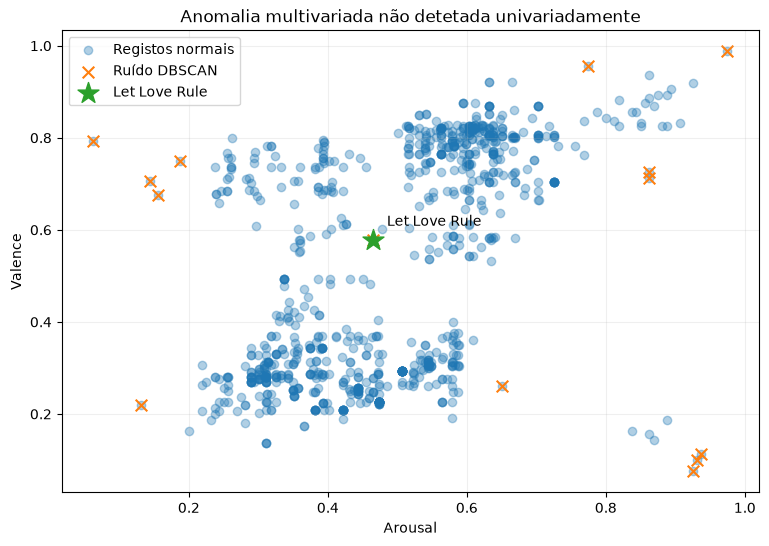

In [42]:
# 4.4.4 - Visualização do registo isolado

# Registo escolhido
registro_444 = candidatos_444[
    candidatos_444["Audio_Song"] == "MT0031893087"
].iloc[0]

plt.figure(figsize=(9, 6))

# Todos os registos
plt.scatter(
    av_train["Arousal"],
    av_train["Valence"],
    alpha=0.35,
    label="Registos normais"
)

# Ruídos encontrados pelo DBSCAN
ruidos_av = av_train.loc[dbscan_noise_av]

plt.scatter(
    ruidos_av["Arousal"],
    ruidos_av["Valence"],
    marker="x",
    s=70,
    label="Ruído DBSCAN"
)

# Destacar Let Love Rule
plt.scatter(
    registro_444["Arousal"],
    registro_444["Valence"],
    marker="*",
    s=250,
    label="Let Love Rule"
)

plt.annotate(
    "Let Love Rule",
    (registro_444["Arousal"], registro_444["Valence"]),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.xlabel("Arousal")
plt.ylabel("Valence")
plt.title("Anomalia multivariada não detetada univariadamente")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 4.4.4 Anomalia apenas multivariada

O registo correspondente à música *Let Love Rule*, de Lenny Kravitz, constitui um exemplo de uma observação que não é particularmente extrema em nenhuma variável considerada isoladamente, mas que apresenta um comportamento invulgar na distribuição conjunta.

O seu Arousal é 0.465 (aproximadamente percentil 43) e a sua Valence é 0.579 (aproximadamente percentil 53). Assim, nenhum dos métodos univariados utilizados (z-score, modified z-score baseado no MAD e Tukey's fences) sinalizou este registo como outlier.

No entanto, o DBSCAN classificou-o como ruído devido à baixa densidade de observações na sua vizinhança no espaço conjunto Arousal-Valence. Isto demonstra que uma observação pode não ser extrema em nenhuma dimensão individual e, ainda assim, ser anómala devido à combinação das suas características.

Neste caso, o método multivariado conseguiu identificar uma estrutura que os métodos univariados não conseguem observar.

In [43]:
# 4.4.5 - Inspecionar os extremos univariados de Arousal e Valence

extremos_univariados = av_train.loc[
    flags_av["Qualquer_univariado"],
    ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
].copy()

# Adicionar informação da música
extremos_univariados = extremos_univariados.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    on="Audio_Song",
    how="left"
)

# Verificar se os valores continuam dentro do domínio válido [0, 1]
extremos_univariados["Arousal_valido"] = extremos_univariados["Arousal"].between(0, 1)
extremos_univariados["Valence_valido"] = extremos_univariados["Valence"].between(0, 1)

print("Registos sinalizados pelos métodos univariados:")
display(extremos_univariados)

Registos sinalizados pelos métodos univariados:


,Audio_Song,Lyric_Song,Arousal,Valence,Artist,Title,Quadrant,Arousal_valido,Valence_valido
0,A095-113,L145-113,0.975,0.9875,Pharrell Williams,Happy,Q1,True,True


In [44]:
# 4.4.5 - Confirmar se o valor extremo existe no dataset original

av_original = pd.read_csv("merge_original/av_values.csv")

happy_original = av_original.loc[
    (av_original["Audio_Song"] == "A095-113") |
    (av_original["Lyric_Song"] == "L145-113")
]

print("Registo correspondente no dataset original:")
display(happy_original)

Registo correspondente no dataset original:


,Audio_Song,Lyric_Song,Arousal,Valence
63,A095-113,L145-113,0.975,0.9875


### 4.4.5 Extremos legítimos

Nem todos os registos sinalizados como outliers correspondem a erros e, por isso, a sinalização estatística não foi utilizada diretamente como critério de remoção.

Um exemplo é a música *Happy*, de Pharrell Williams, que apresenta Arousal = 0.975 e Valence = 0.9875. O registo foi sinalizado pelos métodos univariados devido ao valor extremo de Arousal. No entanto, ambos os valores permanecem dentro do domínio válido [0, 1] e os mesmos valores foram encontrados no conjunto de dados original (`merge_original/av_values.csv`).

Assim, este registo constitui um extremo legítimo e deve ser preservado. O critério de limpeza distingue a deteção estatística da decisão de remoção: um registo sinalizado apenas por ser extremo não é eliminado quando respeita o domínio da variável e é consistente com os dados originais. Desta forma, evita-se remover observações raras, mas válidas, que representam informação real da distribuição.

In [45]:
# 4.4.6 - Caso 1:
# erro que também é detetado como outlier

duration_extremos = train.loc[
    train["Duration"].notna(),
    ["Audio_Song", "Artist", "Title", "Quadrant", "Duration"]
].copy()

# Mostrar os menores e maiores valores de Duration
print("Menores valores de Duration:")
display(duration_extremos.nsmallest(10, "Duration"))

print("\nMaiores valores de Duration:")
display(duration_extremos.nlargest(10, "Duration"))

Menores valores de Duration:


,Audio_Song,Artist,Title,Quadrant,Duration
32,MT0010310891,Slayer,Psychopathy Red,Q2,-1.0
80,MT0004890000,Al Green,Be My Baby,Q1,-1.0
104,MT0002277261,Wolf Parade,Dinner Bells,Q3,-1.0
108,MT0036368550,Taio Cruz,Dynamite,Q1,-1.0
192,MT0002810052,Megadeth,Victory,Q2,-1.0
303,MT0016913402,Dï¿½nï¿½,Dry Lips,Q3,-1.0
440,MT0010702898,Frank Sinatra,I'm Getting Sentimental Over You,Q4,-1.0
497,MT0006833696,Confederate Railroad,When You Leave That Way You Can Never Go Back,Q3,-1.0
622,MT0011924283,Al Green,"Oh, Pretty Woman",Q1,-1.0
644,A130-162,Red House Painters,Song for a Blue Guitar,Q3,-1.0



Maiores valores de Duration:


,Audio_Song,Artist,Title,Quadrant,Duration
216,MT0031834881,bob dylan,Summer Days,Q1,367000.0
697,MT0003496132,Rage Against the Machine,Wake Up,Q2,364000.0
96,MT0010363782,Maxwell,Know These Things: Shouldn't You,Q3,314000.0
819,MT0005023904,Einstï¿½rzende Neubauten,The Garden,Q3,312000.0
97,MT0002510318,Mï¿½m,Green Grass of Tunnel,Q3,291000.0
89,MT0000829765,Trisha Yearwood,When a Love Song Sings the Blues,Q3,267000.0
98,MT0014790813,Fat Joe,Pop U,Q2,264000.0
700,MT0028372740,Prince,Dirty Mind,Q1,255000.0
902,MT0026790435,Chingy,I Like That,Q1,236000.0
252,MT0004869271,Joni Mitchell,This Place,Q3,234000.0


In [46]:
# 4.4.6 - Caso 1: verificar o maior Duration no dataset original

metadata_original = pd.read_csv("merge_original/metadata.csv")

summer_days_original = metadata_original.loc[
    metadata_original["Audio_Song"] == "MT0031834881",
    ["Audio_Song", "Artist", "Title", "Duration"]
]

summer_days_ecac = train.loc[
    train["Audio_Song"] == "MT0031834881",
    ["Audio_Song", "Artist", "Title", "Duration"]
]

print("Dataset danificado:")
display(summer_days_ecac)

print("\nDataset original:")
display(summer_days_original)

Dataset danificado:


,Audio_Song,Artist,Title,Duration
216,MT0031834881,bob dylan,Summer Days,367000.0



Dataset original:


,Audio_Song,Artist,Title,Duration
2089,MT0031834881,Bob Dylan,Summer Days,367.0


In [47]:
# 4.4.6 - Caso 2:
# procurar inconsistências detetáveis por relações entre duas colunas

print("Exemplos de Year, LowestYear e ActualYear:")
display(
    train[
        ["Audio_Song", "Artist", "Title", "Year", "LowestYear", "ActualYear"]
    ].head(20)
)

print("\nTipos das três variáveis:")
print(
    train[
        ["Year", "LowestYear", "ActualYear"]
    ].dtypes
)

print("\nValores únicos de exemplo:")
for col in ["Year", "LowestYear", "ActualYear"]:
    print(f"\n{col}:")
    print(train[col].dropna().astype(str).unique()[:30])

Exemplos de Year, LowestYear e ActualYear:


,Audio_Song,Artist,Title,Year,LowestYear,ActualYear
0,MT0002007417,Marlene Dietrich,Falling in Love Again,27/07/2004,1994-??-??,2004
1,MT0000097948,Nat King Cole,"Baby, Baby All the Time",07/10/2003,NaN,2003
2,MT0031826295,Travis Tritt,Help Me Hold On,1990-??-??,NaN,NaN
3,MT0007860263,Billie Holiday,My Last Affair,11/01/2000,11/01/2000,2000
4,MT0010715611,Revolting Cocks,Mr. Lucky,1993-??-??,1993-??-??,NaN
5,MT0011870505,johnny cash,Old Apache Squaw,1959-??-??,NaN,NaN
6,MT0010100278,The Beatles,When I'm Sixty-Four,01/06/1967,01/06/1967,1967
7,MT0004397754,Sheek Louch,Pressure,08/11/2005,08/11/2005,2005
8,MT0001590644,Paint It Black,We Will Not,19/02/2008,19/02/2008,2008
9,MT0000325093,jennifer lopez,Waiting for Tonight,13/02/2006,NaN,2006



Tipos das três variáveis:
Year          str
LowestYear    str
ActualYear    str
dtype: object

Valores únicos de exemplo:

Year:
<StringArray>
['27/07/2004', '07/10/2003', '1990-??-??', '11/01/2000', '1993-??-??',
 '1959-??-??', '01/06/1967', '08/11/2005', '19/02/2008', '13/02/2006',
 '23/01/2007', '29/09/1998', '03/06/2003', '1986-??-??', '20/08/1991',
 '1983-??-??', '31/07/2001', '20/09/1994', '07/04/2009', '19/06/2007',
 '09/02/1999', '21/11/2006', '21/01/1997', '1997-??-??', '03/08/2004',
 '12/09/2000', '05/05/2009', '1972-??-??', '2009-??-??', '10/08/2004']
Length: 30, dtype: str

LowestYear:
<StringArray>
['1994-??-??', '11/01/2000', '1993-??-??', '01/06/1967', '08/11/2005',
 '19/02/2008', '23/01/2007', '1997-??-??', '1986-??-??', '20/08/1991',
 '1983-??-??', '31/07/2001', '27/02/1996', '09/02/1999', '21/11/2006',
 '21/01/1997', '05/05/2009', '1972-??-??', '10/08/2004', '07/04/1998',
 '08/09/1998', '27/01/2004', '03/10/2000', '1992-??-??', '1984-??-??',
 '27/11/1970', '23/03/199

In [48]:
# 4.4.6 - Caso 2:
# verificar inconsistências entre Year e ActualYear

year_check = train[
    ["Audio_Song", "Artist", "Title", "Year", "ActualYear"]
].copy()

# Extrair um ano de 4 dígitos da coluna Year
year_check["Year_extraido"] = pd.to_numeric(
    year_check["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Converter ActualYear para número
year_check["ActualYear_num"] = pd.to_numeric(
    year_check["ActualYear"],
    errors="coerce"
)

# Selecionar casos em que os dois anos existem, mas discordam
year_inconsistentes = year_check.loc[
    year_check["Year_extraido"].notna()
    & year_check["ActualYear_num"].notna()
    & (year_check["Year_extraido"] != year_check["ActualYear_num"])
].copy()

print("Número de inconsistências Year x ActualYear:")
print(len(year_inconsistentes))

display(year_inconsistentes.head(30))

Número de inconsistências Year x ActualYear:
63


,Audio_Song,Artist,Title,Year,ActualYear,Year_extraido,ActualYear_num
27,MT0002585767,The Davis Sisters,I Forgot More Than You'll Ever Know,03/08/2004,9999,2004.0,9999.0
78,MT0009321428,"Cure, The",This Is a Lie,21/05/1996,1976,1996.0,1976.0
82,MT0007329488,Janet Jackson,control (video mix),26/01/1987,9999,1987.0,9999.0
91,MT0011950450,Neil Diamond,Hark! The Herald Angels Sing,22/09/1992,1978,1992.0,1978.0
111,MT0007438571,Liz Phair,Divorce Song,22/06/1993,1987,1993.0,1987.0
114,MT0005740567,Inner Circle,You've Lost That Lovin' Feelin',21/05/2002,1988,2002.0,1988.0
121,MT0003362617,GARTH BROOKS,Which One of Them,05/05/1998,1979,1998.0,1979.0
125,MT0034410340,John Lee Hooker,No Rollin' Blues,20/02/1996,1900,1996.0,1900.0
144,MT0014798420,Bubba Sparxxx,Ain't Life Grand,04/04/2006,2000,2006.0,2000.0
154,MT0030289937,Louis Armstrong,Billie's Blues,09/10/2001,1987,2001.0,1987.0


In [49]:
# 4.4.6 - Caso 2:
# erro detetado por uma regra entre duas colunas
# LowestYear nunca deve ser posterior a ActualYear

year_rule = train[
    ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
].copy()

# Extrair o ano de LowestYear
year_rule["LowestYear_num"] = pd.to_numeric(
    year_rule["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Converter ActualYear para número
year_rule["ActualYear_num"] = pd.to_numeric(
    year_rule["ActualYear"],
    errors="coerce"
)

# Manter apenas anos plausíveis para este teste
year_rule_validos = year_rule.loc[
    year_rule["LowestYear_num"].between(1900, 2026)
    & year_rule["ActualYear_num"].between(1900, 2026)
].copy()

# Regra do Data Dictionary:
# LowestYear não pode ser posterior a ActualYear
violacoes_year = year_rule_validos.loc[
    year_rule_validos["LowestYear_num"] >
    year_rule_validos["ActualYear_num"]
].copy()

print("Violações da regra LowestYear <= ActualYear:")
print(len(violacoes_year))

display(
    violacoes_year.sort_values(
        ["LowestYear_num", "ActualYear_num"]
    )
)

Violações da regra LowestYear <= ActualYear:
38


,Audio_Song,Artist,Title,LowestYear,ActualYear,LowestYear_num,ActualYear_num
589,MT0028569169,The Louvin Brothers,Are You Teasing Me,1958-??-??,1940,1958.0,1940.0
789,MT0004232099,Ella Fitzgerald,Suppertime,1958-??-??,1957,1958.0,1957.0
379,MT0003536193,Marvin Gaye,Ain't No Mountain High Enough,29/08/1967,1900,1967.0,1900.0
408,MT0013746403,Jean Shepard,Someone's Gotta Cry,1967-??-??,1965,1967.0,1965.0
446,MT0001741017,Elvis Presley,Find out What's Happening,1973-10-??,1972,1973.0,1972.0
709,MT0008813307,bob dylan,"Oh, Sister",16/01/1976,1957,1976.0,1957.0
332,MT0004776609,Ray Conniff,Chances Are,1977-??-??,1969,1977.0,1969.0
612,MT0001313815,Bob Marley,Waiting in Vain,03/06/1977,1970,1977.0,1970.0
826,MT0006633147,Julio Iglesias,Moonlight Lady,1984-??-??,1961,1984.0,1961.0
271,MT0035241675,Crucifucks,I Am the Establishment,1985-??-??,1977,1985.0,1977.0


In [50]:
# 4.4.6 - Confirmar no dataset original a violação entre duas colunas

metadata_original = pd.read_csv("merge_original/metadata.csv")

audio_caso = "MT0001741017"

print("Dataset danificado:")
display(
    train.loc[
        train["Audio_Song"] == audio_caso,
        ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
    ]
)

print("\nDataset original:")
display(
    metadata_original.loc[
        metadata_original["Audio_Song"] == audio_caso,
        ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
    ]
)

Dataset danificado:


,Audio_Song,Artist,Title,LowestYear,ActualYear
446,MT0001741017,Elvis Presley,Find out What's Happening,1973-10-??,1972



Dataset original:


,Audio_Song,Artist,Title,LowestYear,ActualYear
506,MT0001741017,Elvis Presley,Find out What's Happening,1973-10-??,1973


In [51]:
# 4.4.6 - Caso 3:
# verificar se a anomalia multivariada "Let Love Rule"
# corresponde a uma corrupção introduzida no dataset

audio_caso_mv = "MT0031893087"

print("Dataset danificado:")
display(
    av_train.loc[
        av_train["Audio_Song"] == audio_caso_mv,
        ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
    ]
)

print("\nDataset original:")
display(
    av_original.loc[
        av_original["Audio_Song"] == audio_caso_mv,
        ["Audio_Song", "Lyric_Song", "Arousal", "Valence"]
    ]
)

Dataset danificado:


,Audio_Song,Lyric_Song,Arousal,Valence
1256,MT0031893087,MT0031893087,0.465,0.57875



Dataset original:


,Audio_Song,Lyric_Song,Arousal,Valence
2094,MT0031893087,MT0031893087,0.465,0.57875


In [52]:
# 4.4.6 - Procurar, entre as anomalias multivariadas,
# quais foram realmente alteradas no dataset danificado

comparacao_mv = candidatos_444[
    ["Audio_Song", "Artist", "Title", "Quadrant", "Arousal", "Valence"]
].merge(
    av_original[
        ["Audio_Song", "Arousal", "Valence"]
    ],
    on="Audio_Song",
    how="left",
    suffixes=("_danificado", "_original")
)

# Verificar alterações
comparacao_mv["Arousal_alterado"] = (
    comparacao_mv["Arousal_danificado"] !=
    comparacao_mv["Arousal_original"]
)

comparacao_mv["Valence_alterado"] = (
    comparacao_mv["Valence_danificado"] !=
    comparacao_mv["Valence_original"]
)

comparacao_mv["Foi_alterado"] = (
    comparacao_mv["Arousal_alterado"] |
    comparacao_mv["Valence_alterado"]
)

print("Candidatos multivariados:", len(comparacao_mv))
print(
    "Candidatos com Arousal ou Valence diferentes do original:",
    comparacao_mv["Foi_alterado"].sum()
)

display(
    comparacao_mv.sort_values(
        "Foi_alterado",
        ascending=False
    )
)

Candidatos multivariados: 13
Candidatos com Arousal ou Valence diferentes do original: 0


,Audio_Song,Artist,Title,Quadrant,Arousal_danificado,Valence_danificado,Arousal_original,Valence_original,Arousal_alterado,Valence_alterado,Foi_alterado
0,A014,Jamiroquai,Feels Just Like It Should,Q1,0.86250,0.72500,0.86250,0.72500,False,False,False
1,A018,Tony Bennett,Solitude,Q3,0.13125,0.21875,0.13125,0.21875,False,False,False
2,A023,Papa Roach,Last Resort,Q2,0.92500,0.07500,0.92500,0.07500,False,False,False
3,A063-90,Vangelis,Albedo 0.39,Q4,0.15625,0.67500,0.15625,0.67500,False,False,False
4,A101-111,Donna Summer,I Feel Love,Q1,0.77500,0.95625,0.77500,0.95625,False,False,False
5,A119-151,Ciaran McAuley (Lisa Gerrard),On an Ocean,Q4,0.14375,0.70625,0.14375,0.70625,False,False,False
6,A127-133,Vio-Lence,Serial Killer,Q2,0.93125,0.10000,0.93125,0.10000,False,False,False
7,A128-109,Beyoncï¿½,Single Ladies (Put a Ring On It),Q1,0.86250,0.71250,0.86250,0.71250,False,False,False
8,A147-169,Striker,two minutes to midnight,Q2,0.93750,0.11250,0.93750,0.11250,False,False,False
9,A165,Amata,Water Song,Q4,0.18750,0.75000,0.18750,0.75000,False,False,False


In [53]:
# 4.4.6 - Procurar alterações numéricas plausíveis no metadata
# para encontrar um erro que só se destaque multivariadamente

metadata_original = pd.read_csv("merge_original/metadata.csv")

# Juntar dataset danificado e original pelo identificador da música
comparacao_metadata = train.merge(
    metadata_original,
    on="Audio_Song",
    how="inner",
    suffixes=("_danificado", "_original")
)

colunas_numericas_comparar = [
    "Relevance",
    "Duration",
    "Sample",
    "num_Genres",
    "num_MoodsAll"
]

resultados_alteracoes = []

for col in colunas_numericas_comparar:
    col_d = f"{col}_danificado"
    col_o = f"{col}_original"

    if col_d not in comparacao_metadata.columns or col_o not in comparacao_metadata.columns:
        continue

    d = pd.to_numeric(comparacao_metadata[col_d], errors="coerce")
    o = pd.to_numeric(comparacao_metadata[col_o], errors="coerce")

    alterado = (
        d.notna() &
        o.notna() &
        ~np.isclose(d, o, equal_nan=True)
    )

    temp = comparacao_metadata.loc[
        alterado,
        ["Audio_Song", "Artist_danificado", "Title_danificado"]
    ].copy()

    temp["Variavel"] = col
    temp["Valor_danificado"] = d[alterado].values
    temp["Valor_original"] = o[alterado].values

    resultados_alteracoes.append(temp)

alteracoes_numericas = pd.concat(
    resultados_alteracoes,
    ignore_index=True
)

print("Número de alterações numéricas encontradas:")
print(len(alteracoes_numericas))

print("\nAlterações por variável:")
display(
    alteracoes_numericas["Variavel"]
    .value_counts()
    .rename_axis("Variavel")
    .reset_index(name="N_alteracoes")
)

print("\nAlterações encontradas:")
display(alteracoes_numericas)

Número de alterações numéricas encontradas:
94

Alterações por variável:


,Variavel,N_alteracoes
0,Duration,92
1,Relevance,2



Alterações encontradas:


,Audio_Song,Artist_danificado,Title_danificado,Variavel,Valor_danificado,Valor_original
0,MT0004184616,Ella Fitzgerald,I Gotta Right to Sing the Blues,Relevance,1.840000,1.041304
1,MT0002604697,Michael Franks,Like Moon Behind A Cloud,Relevance,1.088161,1.026436
2,MT0015541501,The Jam,'A' Bomb in Wardour Street,Duration,154000.000000,154.000000
3,MT0010630017,Mark Chesnutt,This Heartache Never Sleeps,Duration,228000.000000,228.000000
4,MT0005951020,Spoon,Mountain to Sound,Duration,229000.000000,229.000000
...,...,...,...,...,...,...
89,MT0010777106,Doris Day,That Jane from Maine,Duration,-1.000000,149.000000
90,MT0000672880,The Beach Boys,Amusement Parks U.S.A.,Duration,151000.000000,151.000000
91,MT0009740290,Darius Rucker,Alright,Duration,3.850000,231.000000
92,MT0026790435,Chingy,I Like That,Duration,236000.000000,236.000000


In [54]:
# 4.4.6 - Investigar a alteração subtil de Relevance

audio_michael = "MT0002604697"

# Localizar o registo no train
idx_michael = train.index[
    train["Audio_Song"] == audio_michael
]

print("Índice no train:", idx_michael.tolist())

print("\nRegisto de Michael Franks:")
display(
    train.loc[
        idx_michael,
        ["Audio_Song", "Artist", "Title", "Relevance", "Duration"]
    ]
)

# Verificar os três critérios univariados para Relevance
x = train["Relevance"].dropna()

media = x.mean()
desvio = x.std(ddof=1)
mediana = x.median()
mad = np.median(np.abs(x - mediana))

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1

valor = train.loc[idx_michael[0], "Relevance"]

z = abs((valor - media) / desvio)
modified_z = abs((valor - mediana) / (1.4826 * mad))
tukey = (valor < q1 - 1.5 * iqr) or (valor > q3 + 1.5 * iqr)

print("\nRelevance danificado:", valor)
print("Z-score:", round(z, 4), "-> outlier:", z > 3)
print("Modified Z:", round(modified_z, 4), "-> outlier:", modified_z > 3.5)
print("Tukey -> outlier:", tukey)

# Verificar se o DBSCAN anterior em Relevance + Duration_corrigida o sinalizou
dbscan_series_mv = pd.Series(
    dbscan_noise_mv,
    index=X_mv.index
)

print(
    "\nDBSCAN Relevance + Duration_corrigida -> outlier:",
    bool(dbscan_series_mv.reindex(idx_michael, fill_value=False).iloc[0])
)

Índice no train: [544]

Registo de Michael Franks:


,Audio_Song,Artist,Title,Relevance,Duration
544,MT0002604697,Michael Franks,Like Moon Behind A Cloud,1.088161,NaN



Relevance danificado: 1.088161
Z-score: 0.2636 -> outlier: False
Modified Z: 3.4857 -> outlier: False
Tukey -> outlier: True

DBSCAN Relevance + Duration_corrigida -> outlier: False


In [55]:
# 4.4.6 - Mapear as alterações conhecidas no truth_cells

truth_cells = pd.read_csv("truth/truth_cells.csv")

print("Dimensões:", truth_cells.shape)

print("\nColunas:")
print(truth_cells.columns.tolist())

print("\nPrimeiras alterações:")
display(truth_cells.head(15))

print("\nTipos de alterações / colunas afetadas:")

# Encontrar automaticamente a coluna que identifica
# qual variável do dataset foi modificada
for col in truth_cells.columns:
    print(f"\n{col}:")
    print(truth_cells[col].value_counts(dropna=False).head(20))

Dimensões: (1140, 7)

Colunas:
['song_id', 'column', 'original_value', 'corrupted_value', 'original_is_missing', 'corrupted_is_missing', 'defect_code']

Primeiras alterações:


,song_id,column,original_value,corrupted_value,original_is_missing,corrupted_is_missing,defect_code
0,MT0005330350,Duration,176.0,176000.0,0,0,C1
1,MT0013260233,Duration,177.0,177000.0,0,0,C1
2,A085-69,Duration,212.0,212000.0,0,0,C1
3,MT0002510318,Duration,291.0,291000.0,0,0,C1
4,MT0034410340,Duration,211.0,211000.0,0,0,C1
5,MT0000192982,Duration,165.0,165000.0,0,0,C1
6,MT0007433643,Duration,158.0,158000.0,0,0,C1
7,MT0027149420,Duration,212.0,212000.0,0,0,C1
8,MT0000119987,Duration,245.0,245000.0,0,0,C1
9,MT0001531856,Duration,206.0,206000.0,0,0,C1



Tipos de alterações / colunas afetadas:

song_id:
song_id
MT0007412921    4
MT0034410340    3
MT0027149420    3
MT0012317309    3
MT0034549623    3
MT0002585767    3
MT0004936799    3
A103-99         3
MT0005155949    3
MT0013900095    3
MT0001518335    3
MT0012023721    3
MT0000811743    3
MT0004028719    3
MT0002277261    3
MT0014936205    3
MT0001929641    3
MT0007329488    3
A052            3
MT0003362617    3
Name: count, dtype: int64

column:
column
ActualYear         311
Duration           301
Genres             150
Relevance          122
Artist             120
Title               90
GenreWeights        12
ThemeWeights        11
MoodsAllWeights     11
StyleWeights        11
LowestYear           1
Name: count, dtype: int64

original_value:
original_value
Pop/Rock      38
2005          20
Country       20
2006          18
2000          16
1997          16
2001          13
1996          13
1999          12
2007          12
2003          12
1998          12
2004          12
Rap    

In [56]:
# Resumo compacto das corrupções registadas no truth_cells

print("Colunas do truth_cells:")
print(truth_cells.columns.tolist())

print("\nNúmero de alterações por variável:")
display(
    truth_cells["column"]
    .value_counts()
    .rename_axis("Variável")
    .reset_index(name="N_alterações")
)

Colunas do truth_cells:
['song_id', 'column', 'original_value', 'corrupted_value', 'original_is_missing', 'corrupted_is_missing', 'defect_code']

Número de alterações por variável:


,Variável,N_alterações
0,ActualYear,311
1,Duration,301
2,Genres,150
3,Relevance,122
4,Artist,120
5,Title,90
6,GenreWeights,12
7,ThemeWeights,11
8,MoodsAllWeights,11
9,StyleWeights,11


In [57]:
# 4.4.6 - Procurar corrupção de Relevance detetada apenas multivariadamente

# IDs cuja Relevance foi deliberadamente alterada
truth_relevance = truth_cells.loc[
    truth_cells["column"] == "Relevance",
    ["song_id", "original_value", "corrupted_value"]
].copy()

# DBSCAN anterior, alinhado pelos índices usados em X_mv
dbscan_flag = pd.Series(
    dbscan_noise_mv,
    index=X_mv.index,
    name="DBSCAN"
)

# Flags univariadas de Relevance no train
relevance_flags = pd.DataFrame(index=train.index)

x = train["Relevance"]

media = x.mean()
desvio = x.std()
relevance_flags["Z"] = np.abs((x - media) / desvio) > 3

mediana = x.median()
mad = np.median(np.abs(x.dropna() - mediana))
relevance_flags["MAD"] = (
    np.abs((x - mediana) / (1.4826 * mad)) > 3.5
)

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1
relevance_flags["Tukey"] = (
    (x < q1 - 1.5 * iqr) |
    (x > q3 + 1.5 * iqr)
)

relevance_flags["Univariado"] = relevance_flags.any(axis=1)

# Juntar as corrupções conhecidas com o conjunto de treino
candidatos_rel = train[
    ["Audio_Song", "Artist", "Title", "Relevance"]
].copy()

candidatos_rel["DBSCAN"] = dbscan_flag.reindex(
    candidatos_rel.index,
    fill_value=False
)

candidatos_rel["Univariado"] = relevance_flags["Univariado"]

candidatos_rel = candidatos_rel.merge(
    truth_relevance,
    left_on="Audio_Song",
    right_on="song_id",
    how="inner"
)

# Queremos:
# corrupção real + DBSCAN deteta + nenhum método univariado deteta
caso_joint = candidatos_rel.loc[
    candidatos_rel["DBSCAN"] &
    ~candidatos_rel["Univariado"]
].copy()

print(
    "Corrupções de Relevance detetadas pelo DBSCAN "
    "mas não univariadamente:",
    len(caso_joint)
)

display(caso_joint)

Corrupções de Relevance detetadas pelo DBSCAN mas não univariadamente: 0


,Audio_Song,Artist,Title,Relevance,DBSCAN,Univariado,song_id,original_value,corrupted_value


In [58]:
# 4.4.6 - Investigar os tipos de defeitos introduzidos

print("Defeitos por tipo:")
display(
    truth_cells["defect_code"]
    .value_counts(dropna=False)
    .rename_axis("Defeito")
    .reset_index(name="N")
)

print("\nDefeitos por variável:")
display(
    truth_cells.groupby(
        ["column", "defect_code"],
        dropna=False
    )
    .size()
    .reset_index(name="N")
    .sort_values(["column", "N"], ascending=[True, False])
)

Defeitos por tipo:


,Defeito,N
0,B2,220
1,B1,180
2,B3,150
3,B4,120
4,A2,120
5,A3,90
6,C3,70
7,C1,60
8,C7,45
9,C6,40



Defeitos por variável:


,column,defect_code,N
0,ActualYear,B2,220
3,ActualYear,C6,40
1,ActualYear,C3,35
2,ActualYear,C4,15
4,ActualYear,H5,1
5,Artist,A2,120
6,Duration,B1,180
7,Duration,C1,60
9,Duration,C3,35
8,Duration,C2,25


In [59]:
# 4.4.6 - Inspecionar os cinco casos especiais H1-H5

casos_H = truth_cells.loc[
    truth_cells["defect_code"].isin(["H1", "H2", "H3", "H4", "H5"]),
    [
        "song_id",
        "column",
        "original_value",
        "corrupted_value",
        "defect_code"
    ]
].copy()

# Acrescentar informação da música quando ela estiver no treino
casos_H = casos_H.merge(
    train[["Audio_Song", "Artist", "Title", "Quadrant"]],
    left_on="song_id",
    right_on="Audio_Song",
    how="left"
)

display(
    casos_H[
        [
            "defect_code",
            "song_id",
            "Artist",
            "Title",
            "Quadrant",
            "column",
            "original_value",
            "corrupted_value"
        ]
    ].sort_values("defect_code")
)

,defect_code,song_id,Artist,Title,Quadrant,column,original_value,corrupted_value
0,H1,MT0002604697,Michael Franks,Like Moon Behind A Cloud,Q3,Relevance,1.0264357,1.0881610
1,H2,MT0033459750,Donovan,Epistle to Derroll,Q4,LowestYear,1967-12-??,1962-12-??
2,H3,MT0001453285,NaN,NaN,NaN,Duration,180.0,1680.0
3,H4,MT0004184616,Ella Fitzgerald,I Gotta Right to Sing the Blues,Q3,Relevance,1.0413036,1.8400000
4,H5,A107-115,David Bowie,Let's Dance,Q1,ActualYear,1983,1921


In [60]:
# 4.4.6 - Investigar alterações realizadas ao nível do registo

truth_rows = pd.read_csv("truth/truth_rows.csv")

print("Dimensões:", truth_rows.shape)

print("\nColunas:")
print(truth_rows.columns.tolist())

print("\nPrimeiros registos:")
display(truth_rows.head(20))

# Mostrar distribuição das colunas categóricas
print("\nValores existentes em cada coluna:")
for col in truth_rows.columns:
    print(f"\n{col}:")
    print(truth_rows[col].value_counts(dropna=False).head(20))

Dimensões: (918, 5)

Colunas:
['song_id', 'action', 'duplicate_of', 'defect_code', 'note']

Primeiros registos:


,song_id,action,duplicate_of,defect_code,note
0,A010,removed,NaN,F,"class Q2 subsampled, kept 0.25"
1,A013,removed,NaN,F,"class Q2 subsampled, kept 0.25"
2,A020,removed,NaN,F,"class Q2 subsampled, kept 0.25"
3,A049,removed,NaN,F,"class Q2 subsampled, kept 0.25"
4,A051,removed,NaN,F,"class Q2 subsampled, kept 0.25"
5,A055,removed,NaN,F,"class Q2 subsampled, kept 0.25"
6,A068-167,removed,NaN,F,"class Q2 subsampled, kept 0.25"
7,A074-91,removed,NaN,F,"class Q2 subsampled, kept 0.25"
8,A087-165,removed,NaN,F,"class Q2 subsampled, kept 0.25"
9,A090-94,removed,NaN,F,"class Q2 subsampled, kept 0.25"



Valores existentes em cada coluna:

song_id:
song_id
A010        1
A013        1
A020        1
A049        1
A051        1
A055        1
A068-167    1
A074-91     1
A087-165    1
A090-94     1
A091-95     1
A116-135    1
A131-101    1
A136-97     1
A140-166    1
A142-98     1
A150-132    1
A151-172    1
A172        1
A174        1
Name: count, dtype: int64

action:
action
removed       893
duplicated     25
Name: count, dtype: int64

duplicate_of:
duplicate_of
NaN             893
A071-70           1
A132-121          1
MT0000408441      1
MT0000685538      1
MT0000886390      1
MT0001189913      1
MT0001841416      1
MT0002219182      1
MT0002905185      1
MT0002986568      1
MT0003263304      1
MT0004395306      1
MT0004489039      1
MT0004725405      1
MT0005155949      1
MT0007117290      1
MT0007350911      1
MT0007644103      1
MT0009360971      1
Name: count, dtype: int64

defect_code:
defect_code
F     893
A1     25
Name: count, dtype: int64

note:
note
class Q2 subsampled, kep

In [61]:
# Resumo compacto das alterações ao nível dos registos

print("Número de registos no truth_rows:", len(truth_rows))

print("\nAções:")
display(
    truth_rows["action"]
    .value_counts(dropna=False)
    .rename_axis("Ação")
    .reset_index(name="N")
)

print("\nDefeitos:")
display(
    truth_rows["defect_code"]
    .value_counts(dropna=False)
    .rename_axis("Defeito")
    .reset_index(name="N")
)

print("\nCombinação entre ação e defeito:")
display(
    truth_rows.groupby(
        ["action", "defect_code"],
        dropna=False
    )
    .size()
    .reset_index(name="N")
)

Número de registos no truth_rows: 918

Ações:


,Ação,N
0,removed,893
1,duplicated,25



Defeitos:


,Defeito,N
0,F,893
1,A1,25



Combinação entre ação e defeito:


,action,defect_code,N
0,duplicated,A1,25
1,removed,F,893


In [62]:
# 4.4.6 - Verificar as variáveis disponíveis para o caso H1

audio_h1 = "MT0002604697"

linha_h1 = train.loc[
    train["Audio_Song"] == audio_h1
].copy()

print("Registo H1 completo:")
display(linha_h1.T)

print("\nVariáveis numéricas disponíveis no H1:")
for col in train.select_dtypes(include=np.number).columns:
    print(f"{col}: {linha_h1[col].iloc[0]}")

Registo H1 completo:


,544
Audio_Song,MT0002604697
Lyric_Song,MT0002604697
Quadrant,Q3
AllMusic Id,MT0002604697
AllMusic Extraction Date,Old
Artist,Michael Franks
Title,Like Moon Behind A Cloud
Relevance,1.088161
Year,01/06/1999
LowestYear,01/06/1999



Variáveis numéricas disponíveis no H1:
Relevance: 1.088161
Duration: nan
Sample: 1.0
num_Genres: nan
num_MoodsAll: nan


In [63]:
# 4.4.6 - Inspecionar conjuntamente os defeitos especiais H1-H5

hidden = truth_cells[
    truth_cells["defect_code"].isin(["H1", "H2", "H3", "H4", "H5"])
].copy()

# Informações disponíveis no conjunto de treino
cols_train = [
    "Audio_Song", "Artist", "Title", "Quadrant",
    "Relevance", "Duration", "Year", "LowestYear", "ActualYear"
]

train_info = train[cols_train].copy()

hidden_info = hidden.merge(
    train_info,
    left_on="song_id",
    right_on="Audio_Song",
    how="left"
)

hidden_info["Presente_no_train"] = hidden_info["Audio_Song"].notna()

display(
    hidden_info[
        [
            "defect_code",
            "song_id",
            "Presente_no_train",
            "column",
            "original_value",
            "corrupted_value",
            "Artist",
            "Title",
            "Quadrant",
            "Relevance",
            "Duration",
            "Year",
            "LowestYear",
            "ActualYear"
        ]
    ].sort_values("defect_code")
)

,defect_code,song_id,Presente_no_train,column,original_value,corrupted_value,Artist,Title,Quadrant,Relevance,Duration,Year,LowestYear,ActualYear
0,H1,MT0002604697,True,Relevance,1.0264357,1.0881610,Michael Franks,Like Moon Behind A Cloud,Q3,1.088161,NaN,01/06/1999,01/06/1999,1999
1,H2,MT0033459750,True,LowestYear,1967-12-??,1962-12-??,Donovan,Epistle to Derroll,Q4,1.043157,5.75,1967-12-??,1962-12-??,1967
2,H3,MT0001453285,False,Duration,180.0,1680.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,H4,MT0004184616,True,Relevance,1.0413036,1.8400000,Ella Fitzgerald,I Gotta Right to Sing the Blues,Q3,1.840000,NaN,NaN,NaN,NaN
4,H5,A107-115,True,ActualYear,1983,1921,David Bowie,Let's Dance,Q1,NaN,NaN,NaN,NaN,1921


In [64]:
# 4.4.6 - Verificar H2 e H5 através das relações entre anos

casos_anos = ["MT0033459750", "A107-115"]

verificacao_anos = train.loc[
    train["Audio_Song"].isin(casos_anos),
    [
        "Audio_Song",
        "Artist",
        "Title",
        "Year",
        "LowestYear",
        "ActualYear"
    ]
].copy()

# Extrair um ano numérico de Year e LowestYear
verificacao_anos["Year_num"] = pd.to_numeric(
    verificacao_anos["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

verificacao_anos["LowestYear_num"] = pd.to_numeric(
    verificacao_anos["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

verificacao_anos["ActualYear_num"] = pd.to_numeric(
    verificacao_anos["ActualYear"],
    errors="coerce"
)

# Relações que esperamos que sejam coerentes
verificacao_anos["LowestYear_maior_ActualYear"] = (
    verificacao_anos["LowestYear_num"] >
    verificacao_anos["ActualYear_num"]
)

verificacao_anos["Year_diferente_ActualYear"] = (
    verificacao_anos["Year_num"] !=
    verificacao_anos["ActualYear_num"]
)

display(verificacao_anos)

,Audio_Song,Artist,Title,Year,LowestYear,ActualYear,Year_num,LowestYear_num,ActualYear_num,LowestYear_maior_ActualYear,Year_diferente_ActualYear
190,MT0033459750,Donovan,Epistle to Derroll,1967-12-??,1962-12-??,1967,1967.0,1962.0,1967,False,False
770,A107-115,David Bowie,Let's Dance,NaN,NaN,1921,NaN,NaN,1921,False,True


In [65]:
# 4.4.6 - Investigar H2 na distribuição conjunta LowestYear x ActualYear

anos_joint = train[
    ["Audio_Song", "Artist", "Title", "LowestYear", "ActualYear"]
].copy()

anos_joint["LowestYear_num"] = pd.to_numeric(
    anos_joint["LowestYear"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

anos_joint["ActualYear_num"] = pd.to_numeric(
    anos_joint["ActualYear"],
    errors="coerce"
)

# Apenas registos em que os dois anos estão disponíveis
anos_joint = anos_joint.dropna(
    subset=["LowestYear_num", "ActualYear_num"]
).copy()

# Diferença entre as duas variáveis
anos_joint["Diferenca"] = (
    anos_joint["ActualYear_num"] -
    anos_joint["LowestYear_num"]
)

print("Distribuição da diferença ActualYear - LowestYear:")
display(anos_joint["Diferenca"].describe())

print("\nFrequências das diferenças:")
display(
    anos_joint["Diferenca"]
    .value_counts()
    .sort_index()
    .head(30)
)

print("\nH2 na distribuição conjunta:")
display(
    anos_joint.loc[
        anos_joint["Audio_Song"] == "MT0033459750"
    ]
)

print("\nMaiores diferenças encontradas:")
display(
    anos_joint.sort_values(
        "Diferenca",
        ascending=False
    ).head(20)
)

Distribuição da diferença ActualYear - LowestYear:


count     499.000000
mean       60.028056
std       824.207627
min     -2005.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      8013.000000
Name: Diferenca, dtype: float64


Frequências das diferenças:


Diferenca
-2005.0      1
-2000.0      1
-1999.0      1
-1972.0      1
-1963.0      1
-107.0       1
-106.0       1
-97.0        1
-96.0        2
-67.0        1
-24.0        1
-23.0        2
-20.0        1
-19.0        2
-18.0        4
-17.0        2
-14.0        4
-12.0        1
-10.0        1
-8.0         3
-7.0         2
-6.0         2
-5.0         1
-4.0         1
-3.0         1
-2.0         1
-1.0         3
 0.0       390
 1.0         8
 2.0         5
Name: count, dtype: int64


H2 na distribuição conjunta:


,Audio_Song,Artist,Title,LowestYear,ActualYear,LowestYear_num,ActualYear_num,Diferenca
190,MT0033459750,Donovan,Epistle to Derroll,1962-12-??,1967,1962.0,1967.0,5.0



Maiores diferenças encontradas:


,Audio_Song,Artist,Title,LowestYear,ActualYear,LowestYear_num,ActualYear_num,Diferenca
704,MT0013658337,Elvis Costello,Lovable,21/02/1986,9999,1986.0,9999.0,8013.0
82,MT0007329488,Janet Jackson,control (video mix),26/01/1987,9999,1987.0,9999.0,8012.0
420,MT0001152664,Radiohead,How to Disappear Completely,03/10/2000,9999,2000.0,9999.0,7999.0
516,MT0004290389,Momus,The Lady of Shalott,27/02/2001,9999,2001.0,9999.0,7998.0
780,MT0007906518,The Blackout Pact,"You Punch Me, I Punch You",27/09/2005,9999,2005.0,9999.0,7994.0
351,MT0005540907,Hank Ballard & the Midnighters,Look at Little Sister,1960-??-??,2030,1960.0,2030.0,70.0
430,MT0001169715,Gene Vincent,Red Blue Jeans and a Pony Tail,04/03/1957,2005,1957.0,2005.0,48.0
574,MT0003869539,The Jackson 5,Stand!,20/06/1995,2036,1995.0,2036.0,41.0
721,MT0000169836,Master P,Return of da Don,26/10/1999,2035,1999.0,2035.0,36.0
276,MT0008345160,Freak Nasty,Da' Dip,12/09/2000,2036,2000.0,2036.0,36.0


### 4.4.6 Erros e outliers

A análise realizada confirma que um outlier estatístico não é necessariamente um erro e, inversamente, que alguns erros podem não apresentar valores extremos quando as variáveis são consideradas isoladamente.

**1. Erro que também é um outlier**

O registo *I Gotta Right to Sing the Blues*, de Ella Fitzgerald (`MT0004184616`), constitui um exemplo claro. O valor de `Relevance` foi alterado de aproximadamente 1.041 para 1.84. O valor corrompido é estatisticamente extremo e corresponde efetivamente a uma alteração artificial do conjunto de dados. Neste caso, a deteção de outlier coincide com um erro real.

**2. Erro não detetado univariadamente, mas identificado por uma regra entre duas colunas**

A música *Find out What's Happening*, de Elvis Presley (`MT0001741017`), apresenta `LowestYear = 1973` e `ActualYear = 1972` no conjunto danificado. Individualmente, ambos são anos perfeitamente plausíveis. Contudo, a relação `LowestYear <= ActualYear` é violada. No conjunto original, `ActualYear = 1973`. Assim, uma regra envolvendo duas variáveis identifica um erro que não depende de qualquer valor individualmente extremo.

**3. Erro revelado pela distribuição conjunta**

No registo *Epistle to Derroll*, de Donovan (`MT0033459750`), `LowestYear` foi alterado de 1967 para 1962, enquanto `ActualYear` permanece 1967. Nenhum dos dois valores é individualmente implausível e a regra `LowestYear <= ActualYear` continua satisfeita. Contudo, a distribuição conjunta mostra que `ActualYear` e `LowestYear` coincidem na grande maioria dos registos: os percentis 25%, 50% e 75% da diferença `ActualYear - LowestYear` são todos iguais a zero. A alteração introduz uma combinação incomum que não é revelada pela inspeção isolada das variáveis nem pela regra simples utilizada anteriormente.

**4. Outlier que não é um erro**

A música *Happy*, de Pharrell Williams (`A095-113`), apresenta `Arousal = 0.975` e `Valence = 0.9875`, sendo sinalizada devido à sua posição extrema na distribuição. No entanto, os mesmos valores encontram-se no conjunto de dados original e pertencem ao domínio válido das variáveis. Trata-se, portanto, de um extremo legítimo que deve ser preservado.

Estes exemplos mostram por que motivo a sinalização de uma observação como outlier não deve implicar automaticamente a sua remoção. A decisão deve considerar o domínio das variáveis, relações entre atributos, distribuição conjunta e, quando disponível, evidência proveniente dos dados originais.

In [66]:
# 4.5 - Inspeção inicial dos ficheiros multimédia

from pathlib import Path
from collections import Counter

media_root = Path("../../dataset")

print("Pasta encontrada:", media_root.exists())
print("Caminho:", media_root.resolve())

# Todos os ficheiros existentes
files = [p for p in media_root.rglob("*") if p.is_file()]

print("\nTotal de ficheiros:", len(files))

# Extensões
extensoes = Counter(p.suffix.lower() for p in files)

print("\nExtensões encontradas:")
for ext, n in extensoes.most_common():
    print(f"{ext or '[sem extensão]'}: {n}")

# Estrutura das primeiras pastas
print("\nPastas principais:")
for p in sorted(media_root.iterdir()):
    print(p.name)

# Exemplos de imagens e áudios
image_ext = {".jpg", ".jpeg", ".png"}
audio_ext = {".mp3", ".wav", ".flac", ".m4a"}

images = [p for p in files if p.suffix.lower() in image_ext]
audios = [p for p in files if p.suffix.lower() in audio_ext]

print("\nImagens:", len(images))
print("Áudios:", len(audios))

print("\nExemplos de imagens:")
for p in images[:5]:
    print(p)

print("\nExemplos de áudios:")
for p in audios[:5]:
    print(p)

Pasta encontrada: True
Caminho: C:\Users\Alicia\OneDrive\Documentos\GitHub\TrabECACPL7\dataset\dataset

Total de ficheiros: 6455

Extensões encontradas:
.txt: 2216
.mp3: 2216
.jpg: 2019
[sem extensão]: 3
.csv: 1

Pastas principais:
album_covers
audio
lyrics

Imagens: 2019
Áudios: 2216

Exemplos de imagens:
..\..\dataset\album_covers\Q1\A005.jpg
..\..\dataset\album_covers\Q1\A011.jpg
..\..\dataset\album_covers\Q1\A014.jpg
..\..\dataset\album_covers\Q1\A019.jpg
..\..\dataset\album_covers\Q1\A024.jpg

Exemplos de áudios:
..\..\dataset\audio\Q1\A005.mp3
..\..\dataset\audio\Q1\A011.mp3
..\..\dataset\audio\Q1\A014.mp3
..\..\dataset\audio\Q1\A019.mp3
..\..\dataset\audio\Q1\A022.mp3


Músicas com áudio: 2216
Músicas com capa: 2019
Áudios sem capa: 197

Exemplos de áudios sem capa:
['A022', 'A030', 'A090-94', 'A091-95', 'A109-138', 'A119-151', 'A126-77', 'A132-121', 'A159-164', 'A165', 'A190', 'A195', 'MT0000169836', 'MT0000190640', 'MT0000255724', 'MT0000258646', 'MT0000271970', 'MT0000408441', 'MT0000549945', 'MT0000615489']

Capas analisadas: 2019
Grupos de imagens exatamente repetidas: 182
Ficheiros pertencentes a grupos repetidos: 427

Dimensões mais frequentes:


width  height
600    600       1386
1200   1200        71
600    595         44
       596         28
       597         24
500    500         23
1000   1000        16
600    598         12
       594         12
300    300         10
600    599         10
       593          9
       592          7
598    600          6
1200   1197         6
dtype: int64

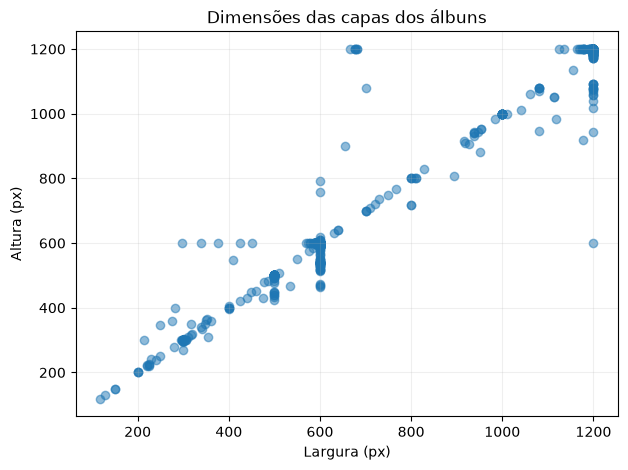

In [67]:
# 4.5.1 - Inspeção das capas dos álbuns

from PIL import Image
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

# IDs dos ficheiros
audio_ids = {p.stem for p in audios}
cover_ids = {p.stem for p in images}

# Capas em falta
missing_covers = sorted(audio_ids - cover_ids)

print("Músicas com áudio:", len(audio_ids))
print("Músicas com capa:", len(cover_ids))
print("Áudios sem capa:", len(missing_covers))

print("\nExemplos de áudios sem capa:")
print(missing_covers[:20])

# Dimensões e hash das imagens
cover_info = []

for p in images:
    try:
        with Image.open(p) as img:
            width, height = img.size

        with open(p, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        cover_info.append({
            "id": p.stem,
            "width": width,
            "height": height,
            "hash": file_hash
        })

    except Exception as e:
        print("Erro ao ler:", p, e)

cover_df = pd.DataFrame(cover_info)

# Imagens exatamente repetidas
duplicate_hashes = (
    cover_df.groupby("hash")
    .size()
    .sort_values(ascending=False)
)

duplicate_hashes = duplicate_hashes[duplicate_hashes > 1]

print("\nCapas analisadas:", len(cover_df))
print("Grupos de imagens exatamente repetidas:", len(duplicate_hashes))
print(
    "Ficheiros pertencentes a grupos repetidos:",
    duplicate_hashes.sum()
)

print("\nDimensões mais frequentes:")
display(
    cover_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

# Gráfico pedido no enunciado
plt.figure(figsize=(7,5))
plt.scatter(
    cover_df["width"],
    cover_df["height"],
    alpha=0.5
)

plt.xlabel("Largura (px)")
plt.ylabel("Altura (px)")
plt.title("Dimensões das capas dos álbuns")
plt.grid(alpha=0.2)
plt.show()

Áudios analisados: 2216

Estatísticas do tamanho dos ficheiros:


count    2216.000000
mean        0.322372
std         0.054927
min         0.054688
25%         0.334122
50%         0.344009
75%         0.344009
max         0.471140
Name: size_mb, dtype: float64


Grupos de áudios exatamente repetidos: 4
Ficheiros pertencentes a grupos repetidos: 8

Registos do dataset sem áudio: 0
Exemplos: []


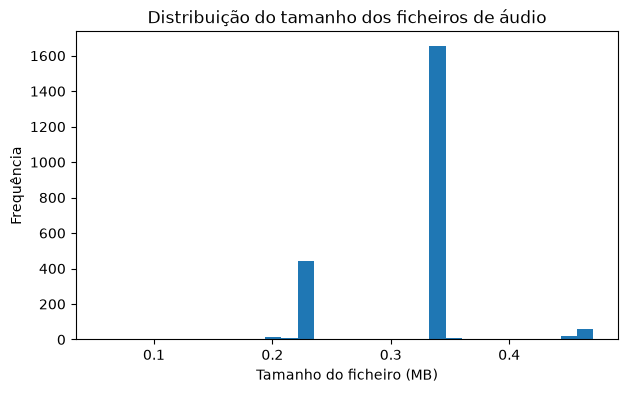

In [70]:
# 4.5.1 - Inspeção dos ficheiros de áudio sem bibliotecas adicionais

import hashlib
import pandas as pd
import matplotlib.pyplot as plt

audio_info = []

for p in audios:
    try:
        with open(p, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        audio_info.append({
            "id": p.stem,
            "size_mb": p.stat().st_size / (1024**2),
            "hash": file_hash
        })

    except Exception:
        pass

audio_df = pd.DataFrame(audio_info)

print("Áudios analisados:", len(audio_df))

print("\nEstatísticas do tamanho dos ficheiros:")
display(audio_df["size_mb"].describe())

# Duplicados exatos
audio_duplicates = (
    audio_df.groupby("hash")
    .size()
    .sort_values(ascending=False)
)

audio_duplicates = audio_duplicates[audio_duplicates > 1]

print("\nGrupos de áudios exatamente repetidos:", len(audio_duplicates))
print(
    "Ficheiros pertencentes a grupos repetidos:",
    audio_duplicates.sum()
)

# Verificar se os IDs do dataset possuem áudio
dataset_ids = set(train["Audio_Song"]).union(set(test["Audio_Song"]))
missing_audio = sorted(dataset_ids - audio_ids)

print("\nRegistos do dataset sem áudio:", len(missing_audio))
print("Exemplos:", missing_audio[:20])

# Distribuição
plt.figure(figsize=(7,4))
plt.hist(audio_df["size_mb"], bins=30)
plt.xlabel("Tamanho do ficheiro (MB)")
plt.ylabel("Frequência")
plt.title("Distribuição do tamanho dos ficheiros de áudio")
plt.show()

## 4.5 Media

### 4.5.1 Inspeção das capas e dos ficheiros de áudio

A inspeção dos ficheiros multimédia identificou 2216 ficheiros de áudio e 2019 capas de álbuns. Assim, existem 197 músicas com áudio disponível mas sem uma capa correspondente. Esta ausência deve ser considerada na utilização da modalidade visual, uma vez que nem todos os registos poderão fornecer informação proveniente da capa.

As dimensões das capas apresentam alguma variabilidade, embora a maioria das imagens se encontre próxima da diagonal largura = altura, indicando uma predominância de capas aproximadamente quadradas. Existem também algumas imagens com proporções e resoluções diferentes, pelo que um eventual modelo baseado em imagens deverá aplicar um procedimento consistente de redimensionamento.

Todos os 2216 ficheiros de áudio foram lidos durante a inspeção e nenhum registo do conjunto de treino ou teste ficou sem um ficheiro de áudio correspondente. O tamanho médio dos ficheiros é aproximadamente 0.322 MB, com valores entre aproximadamente 0.055 MB e 0.471 MB.

Foram ainda encontrados 4 grupos de ficheiros de áudio exatamente repetidos, correspondendo a 8 ficheiros. Esta duplicação deve ser considerada na avaliação, uma vez que conteúdos idênticos não devem fornecer informação artificialmente repetida entre treino e teste.

No conjunto, a principal limitação encontrada nos media é a ausência de capas para parte das músicas. Para o áudio, a cobertura dos registos utilizados é completa.

In [71]:
# 4.6 - Produção dos conjuntos de dados limpos finais

from pathlib import Path
import pandas as pd

output_dir = Path("cleaned")
output_dir.mkdir(exist_ok=True)

# Guardar versões finais
train.to_csv(output_dir / "train_clean_final.csv", index=False)
test.to_csv(output_dir / "test_clean_final.csv", index=False)

print("Train final:", train.shape)
print("Test final:", test.shape)

print("\nValores em falta nas colunas essenciais:")
essential = ["Audio_Song", "Lyric_Song", "Quadrant"]

print("TRAIN")
display(train[essential].isna().sum())

print("TEST")
display(test[essential].isna().sum())

print("\nQuadrantes no train:")
print(train["Quadrant"].value_counts().sort_index())

print("\nQuadrantes no test:")
print(test["Quadrant"].value_counts().sort_index())

print("\nDuplicados exatos:")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())

print("\nSobreposição de Audio_Song entre train e test:")
print(
    len(
        set(train["Audio_Song"]) &
        set(test["Audio_Song"])
    )
)

Train final: (913, 27)
Test final: (409, 27)

Valores em falta nas colunas essenciais:
TRAIN


Audio_Song    0
Lyric_Song    0
Quadrant      0
dtype: int64

TEST


Audio_Song    0
Lyric_Song    0
Quadrant      0
dtype: int64


Quadrantes no train:
Quadrant
Q1    366
Q2    111
Q3    347
Q4     89
Name: count, dtype: int64

Quadrantes no test:
Quadrant
Q1    159
Q2     56
Q3    153
Q4     41
Name: count, dtype: int64

Duplicados exatos:
Train: 0
Test: 0

Sobreposição de Audio_Song entre train e test:
0


=== IMBALANCE.md ===
# Class distribution of this dataset

The quadrant distribution of this dataset is not the distribution of the
published MERGE Bimodal Complete dataset. Two classes were subsampled on
purpose, before any other modification, and the rows removed are listed in
`truth/truth_rows.csv` with the code `F`.

| quadrant | in the published dataset | kept here | fraction |
|---|---|---|---|
| Q1 | 525 | 525 | 1.00 |
| Q2 | 673 | 168 | 0.25 |
| Q3 | 500 | 500 | 1.00 |
| Q4 | 518 | 130 | 0.25 |

Total rows after subsampling: **1323**. Largest class over smallest:
**4.04:1**. A classifier that always answers with the majority
class is right **39.7%** of the time.

The subsampling is uniformly at random within each class, with a fixed seed.
It is not stratified by artist, by year or by anything else, so the group
structure of the surviving rows is the group structure of the original.

## Two things to notice before using this

The two subsampled classes were not chosen for conven

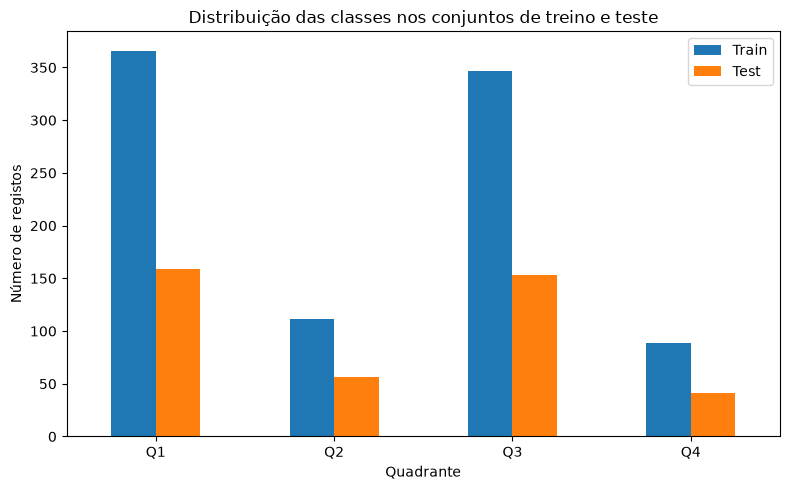

In [72]:
# 5 - Distribuição das classes

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ler as instruções sobre imbalance
imbalance_path = Path("IMBALANCE.md")

if imbalance_path.exists():
    print("=== IMBALANCE.md ===")
    print(imbalance_path.read_text(encoding="utf-8")[:3000])
else:
    print("IMBALANCE.md não encontrado.")

# Distribuição das classes
train_counts = train["Quadrant"].value_counts().sort_index()
test_counts = test["Quadrant"].value_counts().sort_index()

print("\n=== DISTRIBUIÇÃO TRAIN ===")
print(train_counts)

print("\n=== DISTRIBUIÇÃO TEST ===")
print(test_counts)

# Maior / menor classe
maior = train_counts.max()
menor = train_counts.min()
ratio = maior / menor

print("\nMaior classe:", train_counts.idxmax(), "-", maior)
print("Menor classe:", train_counts.idxmin(), "-", menor)
print("Razão maior/menor:", round(ratio, 2))

# Baseline que prevê sempre a classe maior
majority_accuracy = maior / len(train)

print(
    "\nAccuracy de um classificador que prevê sempre",
    train_counts.idxmax(),
    ":",
    round(majority_accuracy, 4),
    f"({majority_accuracy*100:.2f}%)"
)

# Frequências relativas
print("\nPercentagens por classe:")
print((train_counts / len(train) * 100).round(2))

# Gráfico
class_distribution = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})

class_distribution.plot(
    kind="bar",
    figsize=(8,5)
)

plt.xlabel("Quadrante")
plt.ylabel("Número de registos")
plt.title("Distribuição das classes nos conjuntos de treino e teste")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Distribuição das classes

### 5.1 Distribuição e grau de desequilíbrio

Após a limpeza, o conjunto de treino contém 913 registos, distribuídos da seguinte forma:

- Q1: 366 registos
- Q2: 111 registos
- Q3: 347 registos
- Q4: 89 registos

A maior classe é Q1, com 366 observações, enquanto a menor é Q4, com 89. A razão entre a maior e a menor classe é aproximadamente 4.11:1, evidenciando um desequilíbrio relevante entre os quadrantes.

O conjunto de teste apresenta uma distribuição semelhante, com 159 registos em Q1, 56 em Q2, 153 em Q3 e 41 em Q4.

### 5.2 Impacto nas métricas de avaliação

Neste cenário, a accuracy isolada deixa de ser uma medida suficientemente informativa. Um modelo pode obter um resultado aparentemente razoável favorecendo sistematicamente as classes mais frequentes, mesmo apresentando um desempenho muito fraco nas classes minoritárias.

Por esse motivo, métricas como macro F1-score, balanced accuracy e recall por classe são mais adequadas para complementar a accuracy. O macro F1 atribui a mesma importância a cada classe, independentemente da sua frequência, enquanto a balanced accuracy considera o recall de cada classe de forma equilibrada.

### 5.3 Classificador da classe maioritária

Um classificador trivial que previsse Q1 para todos os registos obteria aproximadamente 40.1% de accuracy no conjunto de treino, apesar de não possuir qualquer capacidade real de distinguir os quatro quadrantes.

Este baseline demonstra por que motivo uma accuracy próxima de 40% não representa necessariamente aprendizagem útil neste problema. Os resultados dos modelos posteriores deverão, portanto, ser comparados com este baseline e avaliados também através de métricas sensíveis ao desempenho das classes minoritárias.

In [73]:
# 4.6.2 - Custo das decisões de limpeza

decision_cost = pd.DataFrame([
    {
        "Decisão": "Remoção de duplicados exatos",
        "Registos removidos": "já contabilizados na limpeza",
        "Valores substituídos": 0,
        "Informação perdida": "Registos redundantes"
    },
    {
        "Decisão": "Remoção de sobreposição entre treino e teste",
        "Registos removidos": 1,
        "Valores substituídos": 0,
        "Informação perdida": "1 registo do treino"
    },
    {
        "Decisão": "Preservação de outliers legítimos",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Nenhuma"
    },
    {
        "Decisão": "Capas ausentes",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Modalidade visual indisponível para 197 músicas"
    },
    {
        "Decisão": "Áudios duplicados",
        "Registos removidos": 0,
        "Valores substituídos": 0,
        "Informação perdida": "Nenhuma; duplicações identificadas para controlo"
    }
])

display(decision_cost)

,Decisão,Registos removidos,Valores substituídos,Informação perdida
0,Remoção de duplicados exatos,já contabilizados na limpeza,0,Registos redundantes
1,Remoção de sobreposição entre treino e teste,1,0,1 registo do treino
2,Preservação de outliers legítimos,0,0,Nenhuma
3,Capas ausentes,0,0,Modalidade visual indisponível para 197 músicas
4,Áudios duplicados,0,0,Nenhuma; duplicações identificadas para controlo


### 4.6 Conjunto de dados limpo

Após a aplicação das decisões de limpeza, o conjunto final contém 913 registos de treino e 409 registos de teste, ambos com 27 atributos. Não existem valores em falta nas colunas essenciais `Audio_Song`, `Lyric_Song` e `Quadrant`, nem duplicados exatos nos conjuntos finais.

A separação entre treino e teste foi preservada durante todo o processo. As decisões de deteção de outliers não implicaram a remoção automática de observações: extremos legítimos foram mantidos sempre que não existia evidência suficiente de erro.

A tabela de custos resume o impacto das principais decisões tomadas. A ausência de 197 capas não levou à eliminação dos respetivos registos, uma vez que as restantes modalidades continuam disponíveis. Da mesma forma, os ficheiros de áudio repetidos foram identificados para controlo, mas não removidos automaticamente.

O resultado é um conjunto de dados mais consistente, preservando simultaneamente a maior quantidade possível de informação útil para as etapas posteriores de modelação.